# Comptage et segmentation des cellules sanguines par morphologie mathématique

**Plan du notebook**
| Partie | Dataset | Contenu |
|---|---|---|
| 0 | — | Installation, téléchargement des données |
| 1 | Masques (1209 images) | Exploration HSV, choix du canal |
| 2 | Masques — **train** | Choix des opérations morphologiques (Dice) |
| 3 | Masques — train | **Comptage** : nombre réel (masque GT) vs prédit (watershed + granulométrie) |
| 4 | Masques — train | **Réglage** des paramètres du watershed |
| 5 | Masques — **test** | **Évaluation finale** : Dice, IoU, comptage, temps |
| 6 | BCCD (364 images) | Comptage avec les boîtes (test de généralisation) |

**Règle** : tous les choix sont faits sur le **train** ; le **test** n'est utilisé qu'une seule fois, en Partie 5.

**Chaque jour (démarrage rapide pour la Partie 3 et la suite)**
1. Exécuter **la première cellule** (connexion à Drive).
2. Descendre directement à la **Partie 3** : exécuter **3.1** (fonctions) puis **3.1 bis** (copie locale des masques).
3. Continuer avec les cellules suivantes.

⚠️ **Ne pas utiliser « Run all »** : les cellules des Parties 1–2 refont de longs calculs sur 1063 images (leurs résultats sont déjà sauvegardés et résumés dans le tableau de la Partie 2).

Menus Colab utiles : **Runtime → Interrupt execution** (arrêter), **Runtime → Disconnect and delete runtime** (repartir à zéro).

# PARTIE 0 — Installation et données

In [ ]:
!pip install -q opencv-python-headless scikit-image kaggle

import os, shutil
from google.colab import drive
if not os.path.ismount('/content/drive'):
    shutil.rmtree('/content/drive', ignore_errors=True)   # dossier local créé par erreur (pas votre Drive)
    drive.mount('/content/drive')

import os
ROOT = '/content/drive/MyDrive/projet_morpho'   # tout sera sauvegardé ici
DATA = f'{ROOT}/data'
os.makedirs(DATA, exist_ok=True)
print('Dossier projet :', ROOT)

Mounted at /content/drive
Dossier projet : /content/drive/MyDrive/projet_morpho


In [ ]:
BCCD_DIR = f'{DATA}/BCCD_Dataset'
if not os.path.exists(BCCD_DIR):
    !git clone -q https://github.com/Shenggan/BCCD_Dataset.git "{BCCD_DIR}"
print(os.listdir(f'{BCCD_DIR}/BCCD'))

['Annotations', 'ImageSets', 'JPEGImages']


In [ ]:
import glob, xml.etree.ElementTree as ET
import pandas as pd

rows = []
for xml_path in sorted(glob.glob(f'{BCCD_DIR}/BCCD/Annotations/*.xml')):
    root = ET.parse(xml_path).getroot()
    for obj in root.findall('object'):
        bb = obj.find('bndbox')
        x1, y1, x2, y2 = (int(float(bb.find(k).text)) for k in ['xmin','ymin','xmax','ymax'])
        rows.append(dict(image=os.path.basename(xml_path).replace('.xml','.jpg'),
                         cls=obj.find('name').text, x1=x1, y1=y1, x2=x2, y2=y2,
                         w=x2-x1, h=y2-y1))

boxes = pd.DataFrame(rows)
print('Images annotées :', boxes.image.nunique())
print('\nCellules par classe :'); print(boxes.cls.value_counts())
print('\nTaille moyenne (px) par classe :'); print(boxes.groupby('cls')[['w','h']].mean().round(1))
boxes.to_csv(f'{DATA}/bccd_boxes.csv', index=False)

Images annotées : 364

Cellules par classe :
cls
RBC          4155
WBC           372
Platelets     361
Name: count, dtype: int64

Taille moyenne (px) par classe :
               w      h
cls                    
Platelets   41.6   40.2
RBC        104.4  100.3
WBC        194.0  175.6


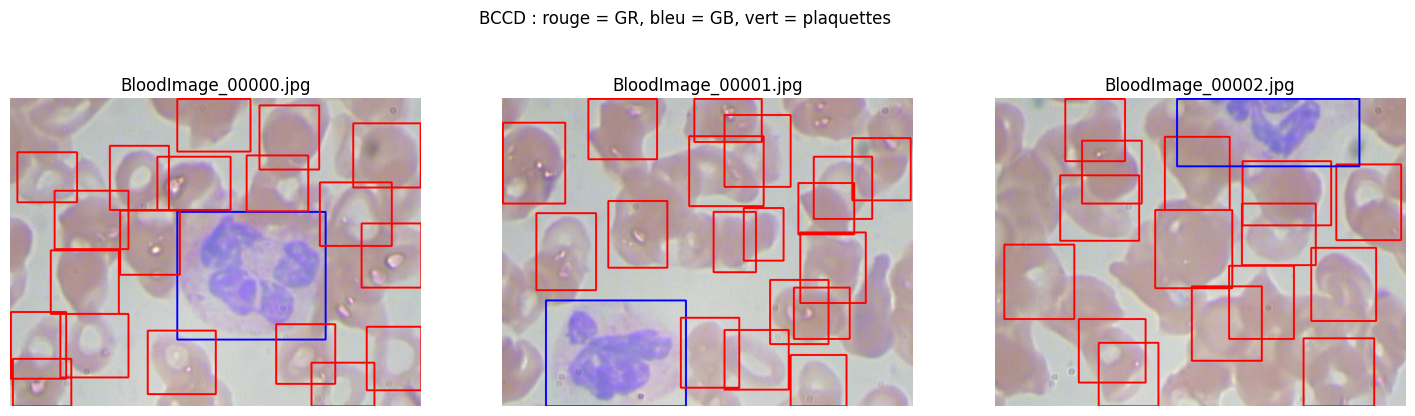

In [ ]:
import cv2, matplotlib.pyplot as plt

COLORS = {'RBC': (255,0,0), 'WBC': (0,0,255), 'Platelets': (0,200,0)}

def show_bccd(name, ax):
    img = cv2.cvtColor(cv2.imread(f'{BCCD_DIR}/BCCD/JPEGImages/{name}'), cv2.COLOR_BGR2RGB)
    for _, r in boxes[boxes.image == name].iterrows():
        cv2.rectangle(img, (r.x1, r.y1), (r.x2, r.y2), COLORS.get(r.cls, (0,0,0)), 2)
    ax.imshow(img); ax.set_title(name); ax.axis('off')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, boxes.image.unique()[:3]):
    show_bccd(name, ax)
plt.suptitle('BCCD : rouge = GR, bleu = GB, vert = plaquettes'); plt.show()

In [ ]:
!pip install -q -U kaggle

from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

MASK_DIR = f'{DATA}/bccd_mask'
if not os.path.exists(MASK_DIR) or not os.listdir(MASK_DIR):
    !kaggle datasets download -d jeetblahiri/bccd-dataset-with-mask -p "{MASK_DIR}" --unzip -q

for d, sub, fs in os.walk(MASK_DIR):
    depth = d[len(MASK_DIR):].count(os.sep)
    if depth <= 3:
        print('  '*depth + os.path.basename(d) + f'/  ({len(fs)} fichiers)')

bccd_mask/  (0 fichiers)
  BCCD Dataset with mask/  (0 fichiers)
    test/  (0 fichiers)
      mask/  (159 fichiers)
      original/  (159 fichiers)
    train/  (0 fichiers)
      mask/  (1169 fichiers)
      original/  (1169 fichiers)


In [ ]:
from pathlib import Path

def find_pairs(root):
    pairs = []
    for orig_dir in Path(root).rglob('original'):
        mask_dir = orig_dir.parent / 'mask'
        if not (orig_dir.is_dir() and mask_dir.is_dir()):
            continue
        split = orig_dir.parent.name            # 'train' ou 'test'
        for img in sorted(orig_dir.iterdir()):
            m = mask_dir / img.name
            if m.exists():
                pairs.append((split, str(img), str(m)))
    return pd.DataFrame(pairs, columns=['split', 'image', 'mask'])

pairs = find_pairs(MASK_DIR)
print('Nombre de paires image/masque :', len(pairs))
print(pairs.split.value_counts())
assert len(pairs) > 0, "Toujours aucune paire : envoyez-moi la sortie du diagnostic"
pairs.to_csv(f'{DATA}/bccd_mask_pairs.csv', index=False)

Nombre de paires image/masque : 1209
split
train    1063
test      146
Name: count, dtype: int64


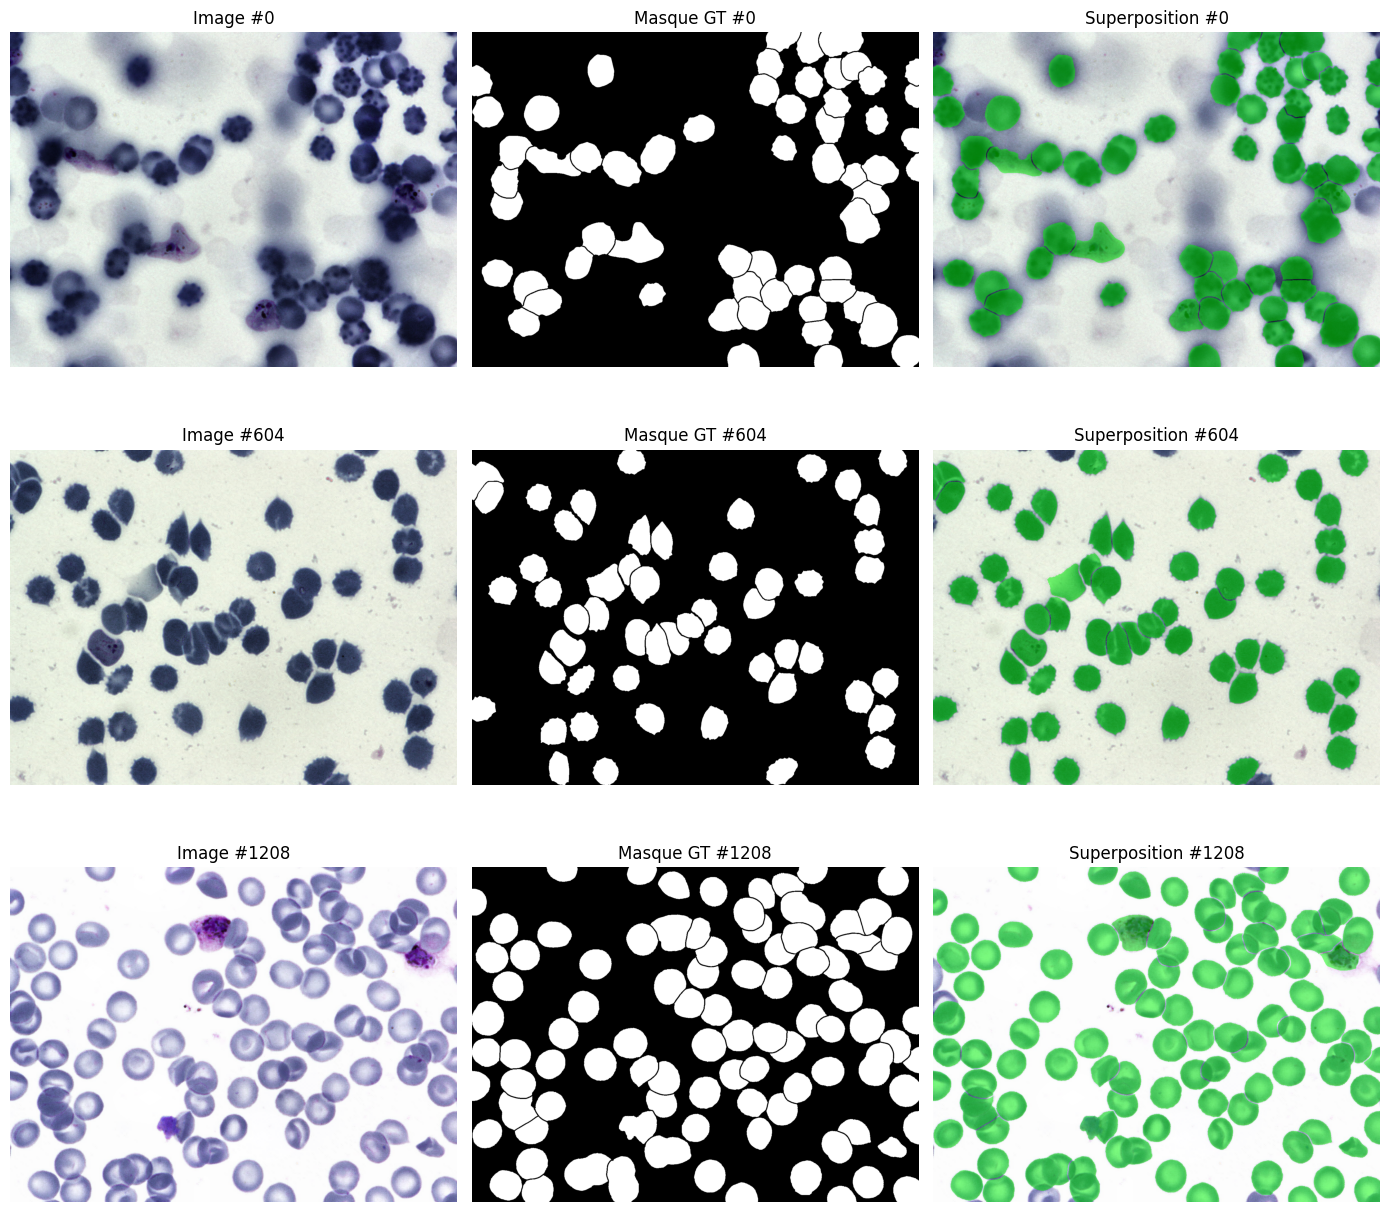

Taille image : (1200, 1600, 3) | fraction de pixels « cellule » : 0.435


In [ ]:
def load_pair(i):
    img = cv2.cvtColor(cv2.imread(pairs.image[i]), cv2.COLOR_BGR2RGB)
    gt  = cv2.imread(pairs['mask'][i], cv2.IMREAD_GRAYSCALE) > 127
    if gt.shape != img.shape[:2]:
        gt = cv2.resize(gt.astype('uint8'), img.shape[1::-1], interpolation=cv2.INTER_NEAREST) > 0
    return img, gt

fig, axes = plt.subplots(3, 3, figsize=(14, 13))
for row, i in zip(axes, [0, len(pairs)//2, len(pairs)-1]):
    img, gt = load_pair(i)
    overlay = img.copy()
    overlay[gt] = (0.5*overlay[gt] + [0, 127, 0]).astype('uint8')
    for ax, im, t in zip(row, [img, gt, overlay], ['Image', 'Masque GT', 'Superposition']):
        ax.imshow(im, cmap='gray'); ax.set_title(f'{t} #{i}'); ax.axis('off')
plt.tight_layout(); plt.show()
print('Taille image :', img.shape, '| fraction de pixels « cellule » :', round(gt.mean(), 3))

# PARTIE 1 — Exploration HSV et choix du canal (dataset « masques »)

Résultat (train, 1063 images) : **canal S + Otsu (binaire)** → Dice = 0,899 (V inversé : 0,897 ; H : 0,707).

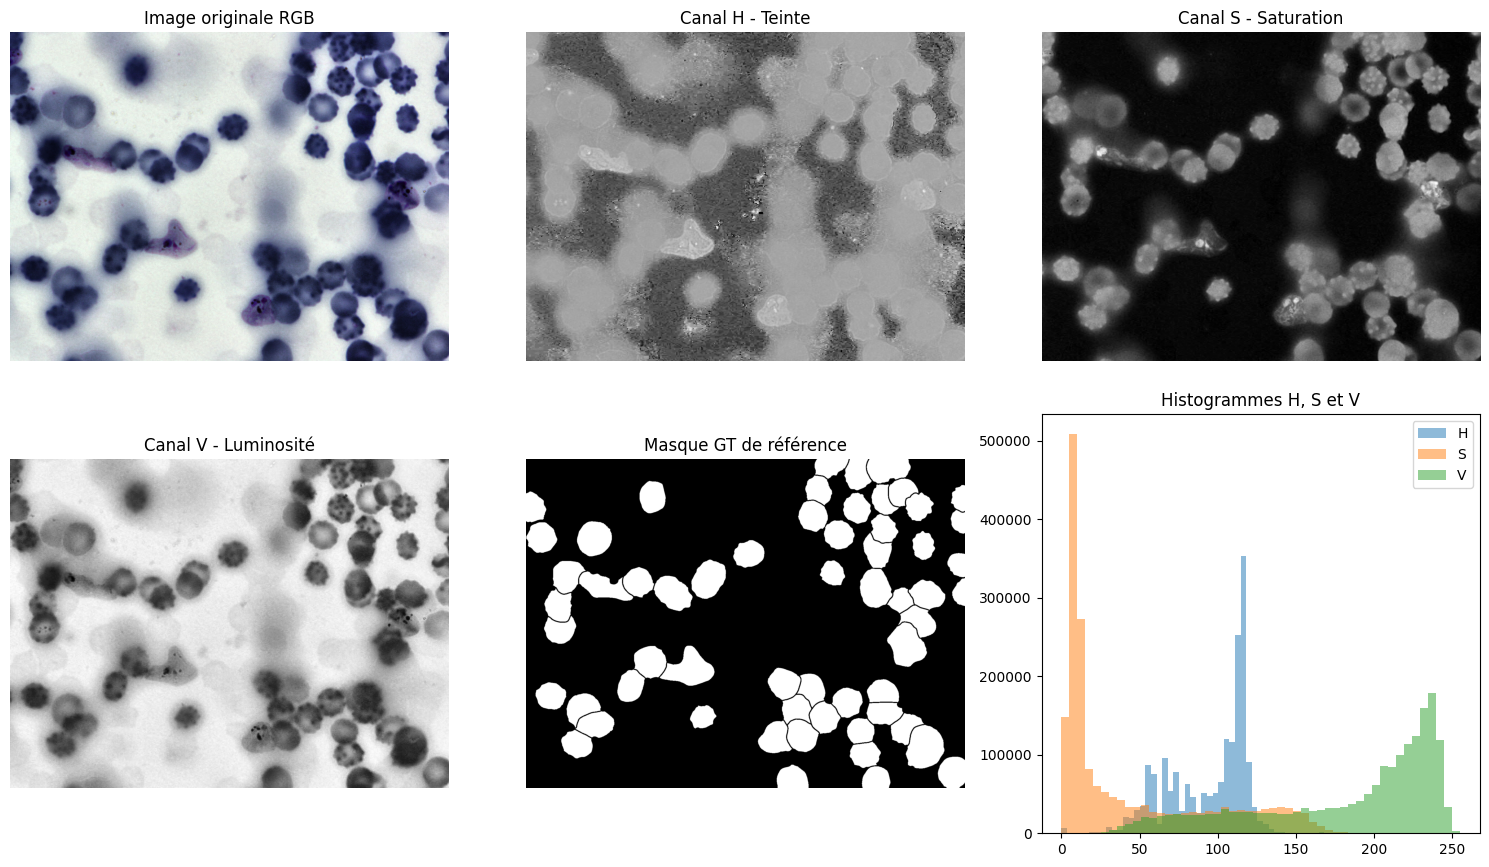

Dimensions RGB : (1200, 1600, 3)
Dimensions HSV : (1200, 1600, 3)
Valeurs H : 0 - 179
Valeurs S : 0 - 255
Valeurs V : 0 - 255


In [ ]:

# Étape 7 : première exploration HSV

import cv2
import matplotlib.pyplot as plt
import numpy as np

# Sélectionner une image du dataset avec son masque GT
img_rgb, gt = load_pair(0)

# Conversion RGB vers HSV
img_hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)

# Séparation des trois canaux
H, S, V = cv2.split(img_hsv)

# Affichage comparatif
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

axes[0, 0].imshow(img_rgb)
axes[0, 0].set_title("Image originale RGB")

axes[0, 1].imshow(H, cmap="gray", vmin=0, vmax=179)
axes[0, 1].set_title("Canal H - Teinte")

axes[0, 2].imshow(S, cmap="gray", vmin=0, vmax=255)
axes[0, 2].set_title("Canal S - Saturation")

axes[1, 0].imshow(V, cmap="gray", vmin=0, vmax=255)
axes[1, 0].set_title("Canal V - Luminosité")

axes[1, 1].imshow(gt, cmap="gray")
axes[1, 1].set_title("Masque GT de référence")

# Histogrammes des canaux
axes[1, 2].hist(H.ravel(), bins=50, alpha=0.5, label="H")
axes[1, 2].hist(S.ravel(), bins=50, alpha=0.5, label="S")
axes[1, 2].hist(V.ravel(), bins=50, alpha=0.5, label="V")
axes[1, 2].set_title("Histogrammes H, S et V")
axes[1, 2].legend()

for ax in axes.flat:
    if ax not in [axes[1, 2]]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Dimensions RGB :", img_rgb.shape)
print("Dimensions HSV :", img_hsv.shape)
print("Valeurs H :", H.min(), "-", H.max())
print("Valeurs S :", S.min(), "-", S.max())
print("Valeurs V :", V.min(), "-", V.max())


In [ ]:

# Conversion HSV avec sauvegarde et reprise automatique

import os
import cv2
import pandas as pd
from tqdm.auto import tqdm

HSV_DIR = f'{DATA}/HSV'
CSV_HSV = f'{DATA}/bccd_hsv_pairs.csv'
os.makedirs(HSV_DIR, exist_ok=True)

# Vérifier si la conversion a déjà été effectuée
if os.path.exists(CSV_HSV):
    saved_pairs = pd.read_csv(CSV_HSV)

    # Vérifier que toutes les images HSV sauvegardées existent
    files_exist = (
        len(saved_pairs) > 0
        and saved_pairs['hsv_image'].map(os.path.isfile).all()
    )

    # Vérifier que le nombre de paires correspond au dataset actuel
    if files_exist and len(saved_pairs) == len(pairs):
        hsv_pairs = saved_pairs
        print("Conversion HSV déjà effectuée : chargement des résultats.")
    else:
        print("Sauvegarde incomplète : nouvelle conversion nécessaire.")
        hsv_pairs = None
else:
    hsv_pairs = None

# Convertir uniquement si aucune sauvegarde valide n'est disponible
if hsv_pairs is None:
    hsv_results = []
    errors = 0

    for _, row in tqdm(
        pairs.iterrows(),
        total=len(pairs),
        desc="Conversion HSV"
    ):
        img_bgr = cv2.imread(row['image'])

        if img_bgr is None:
            errors += 1
            continue

        img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)

        split = row['split']
        filename = os.path.basename(row['image'])

        output_dir = os.path.join(HSV_DIR, split)
        os.makedirs(output_dir, exist_ok=True)

        output_path = os.path.join(output_dir, filename)

        if not cv2.imwrite(output_path, img_hsv):
            errors += 1
            continue

        hsv_results.append({
            'split': split,
            'image': row['image'],
            'mask': row['mask'],
            'hsv_image': output_path
        })

    hsv_pairs = pd.DataFrame(hsv_results)
    hsv_pairs.to_csv(CSV_HSV, index=False)

    print("Nouvelle conversion terminée.")
    print("Images illisibles ou non sauvegardées :", errors)

print("\nNombre d'images HSV disponibles :", len(hsv_pairs))
print(hsv_pairs['split'].value_counts())
print("Fichier de sauvegarde :", CSV_HSV)


Conversion HSV déjà effectuée : chargement des résultats.

Nombre d'images HSV disponibles : 1209
split
train    1063
test      146
Name: count, dtype: int64
Fichier de sauvegarde : /content/drive/MyDrive/projet_morpho/data/bccd_hsv_pairs.csv


In [ ]:

# Étape 8 bis : évaluation des canaux HSV sur le dataset

import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

def calculate_dice(pred, target):
    pred = pred.astype(bool)
    target = target.astype(bool)
    denominator = pred.sum() + target.sum()

    if denominator == 0:
        return 1.0

    return 2 * np.logical_and(pred, target).sum() / denominator


# Choisir le canal sur train uniquement
train_pairs = hsv_pairs[hsv_pairs['split'] == 'train']

scores = []

for _, row in tqdm(
    train_pairs.iterrows(),
    total=len(train_pairs),
    desc="Évaluation sur train"
):
    # Charger l'image HSV
    img_hsv = cv2.imread(row['hsv_image'])
    if img_hsv is None:
        continue

    H, S, V = cv2.split(img_hsv)

    # Charger le masque GT correspondant
    gt = cv2.imread(row['mask'], cv2.IMREAD_GRAYSCALE)
    if gt is None:
        continue

    gt = gt > 127

    if gt.shape != H.shape:
        gt = cv2.resize(
            gt.astype(np.uint8),
            (H.shape[1], H.shape[0]),
            interpolation=cv2.INTER_NEAREST
        ) > 0

    channels = {'H': H, 'S': S, 'V': V}

    for name, channel in channels.items():
        # Tester les deux polarités d'Otsu
        _, normal = cv2.threshold(
            channel, 0, 255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        _, inverse = cv2.threshold(
            channel, 0, 255,
            cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
        )

        scores.append({
            'image': row['image'],
            'Canal': name,
            'Polarité': 'Binaire',
            'Dice': calculate_dice(normal > 0, gt)
        })

        scores.append({
            'image': row['image'],
            'Canal': name,
            'Polarité': 'Binaire inversé',
            'Dice': calculate_dice(inverse > 0, gt)
        })

scores_df = pd.DataFrame(scores)

# Moyenne et variabilité des scores sur les images train
summary = (
    scores_df
    .groupby(['Canal', 'Polarité'])['Dice']
    .agg(['mean', 'std', 'count'])
    .reset_index()
    .sort_values('mean', ascending=False)
)

summary = summary.rename(columns={
    'mean': 'Dice moyen',
    'std': 'Écart-type',
    'count': 'Nombre images'
})

display(summary.round(4))


Évaluation sur train:   0%|          | 0/1063 [00:00<?, ?it/s]

,Canal,Polarité,Dice moyen,Écart-type,Nombre images
2,S,Binaire,0.8991,0.0895,1063
5,V,Binaire inversé,0.8973,0.0603,1063
0,H,Binaire,0.7074,0.2111,1063
4,V,Binaire,0.0863,0.0620,1063
3,S,Binaire inversé,0.0832,0.0826,1063
1,H,Binaire inversé,0.0075,0.0261,1063


In [ ]:
# Étape 8 ter : sauvegarder les résultats de l'évaluation HSV

import os

# Dossier de sauvegarde
RESULTS_DIR = f'{ROOT}/results'
os.makedirs(RESULTS_DIR, exist_ok=True)

# Sauvegarder les scores de chaque image
scores_path = f'{RESULTS_DIR}/otsu_hsv_scores_train.csv'
scores_df.to_csv(scores_path, index=False)

# Sauvegarder le résumé par canal et polarité
summary_path = f'{RESULTS_DIR}/otsu_hsv_summary_train.csv'
summary.to_csv(summary_path, index=False)

print("Sauvegarde terminée !")
print(f"Scores détaillés : {scores_path}")
print(f"Résumé des résultats : {summary_path}")

Sauvegarde terminée !
Scores détaillés : /content/drive/MyDrive/projet_morpho/results/otsu_hsv_scores_train.csv
Résumé des résultats : /content/drive/MyDrive/projet_morpho/results/otsu_hsv_summary_train.csv


In [ ]:
# Afficher la meilleure configuration sur train
best_result = summary.iloc[0]

print("Meilleur canal :", best_result['Canal'])
print("Polarité :", best_result['Polarité'])
print("Dice moyen :", round(best_result['Dice moyen'], 4))

Meilleur canal : S
Polarité : Binaire
Dice moyen : 0.8991


In [ ]:

import os
import cv2
import pandas as pd
from tqdm.auto import tqdm

# ============================================================
# 1. Chemins de sauvegarde
# ============================================================

S_MASK_DIR = f'{DATA}/S_binary'
CSV_S_MASKS = f'{DATA}/bccd_s_binary_pairs.csv'

os.makedirs(S_MASK_DIR, exist_ok=True)

# ============================================================
# 2. Vérifier si les masques ont déjà été générés
# ============================================================

if os.path.exists(CSV_S_MASKS):
    saved_masks = pd.read_csv(CSV_S_MASKS)

    files_exist = (
        len(saved_masks) > 0
        and saved_masks['s_mask'].map(os.path.isfile).all()
    )

    if files_exist and len(saved_masks) == len(hsv_pairs):
        s_masks_df = saved_masks
        print("Masques S binaires déjà disponibles : chargement.")
    else:
        print("Sauvegarde incomplète : génération des masques.")
        s_masks_df = None
else:
    s_masks_df = None

# ============================================================
# 3. Extraire S et appliquer le seuillage d'Otsu
# ============================================================

if s_masks_df is None:
    results = []
    errors = 0

    for _, row in tqdm(
        hsv_pairs.iterrows(),
        total=len(hsv_pairs),
        desc="Création des masques S binaires"
    ):
        # Charger l'image HSV déjà sauvegardée
        img_hsv = cv2.imread(row['hsv_image'])

        if img_hsv is None:
            errors += 1
            continue

        # Extraire uniquement le canal S
        _, S, _ = cv2.split(img_hsv)

        # Seuillage d'Otsu : polarité BINAIRE
        _, binary_mask = cv2.threshold(
            S,
            0,
            255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        # Conserver le split train/test
        split = row['split']

        # Nom du fichier de sortie
        filename = os.path.basename(row['hsv_image'])
        output_dir = os.path.join(S_MASK_DIR, split)
        os.makedirs(output_dir, exist_ok=True)

        output_path = os.path.join(output_dir, filename)

        if not cv2.imwrite(output_path, binary_mask):
            errors += 1
            continue

        results.append({
            'split': split,
            'image': row['image'],
            'mask': row['mask'],
            'hsv_image': row['hsv_image'],
            's_mask': output_path
        })

    s_masks_df = pd.DataFrame(results)
    s_masks_df.to_csv(CSV_S_MASKS, index=False)

    print("Génération des masques terminée.")
    print("Images non traitées ou non sauvegardées :", errors)

# ============================================================
# 4. Résumé
# ============================================================

print("\nNombre de masques S binaires :", len(s_masks_df))
print("\nRépartition des données :")
print(s_masks_df['split'].value_counts())

print("\nDossier des masques :", S_MASK_DIR)
print("Fichier CSV :", CSV_S_MASKS)


Masques S binaires déjà disponibles : chargement.

Nombre de masques S binaires : 1209

Répartition des données :
split
train    1063
test      146
Name: count, dtype: int64

Dossier des masques : /content/drive/MyDrive/projet_morpho/data/S_binary
Fichier CSV : /content/drive/MyDrive/projet_morpho/data/bccd_s_binary_pairs.csv


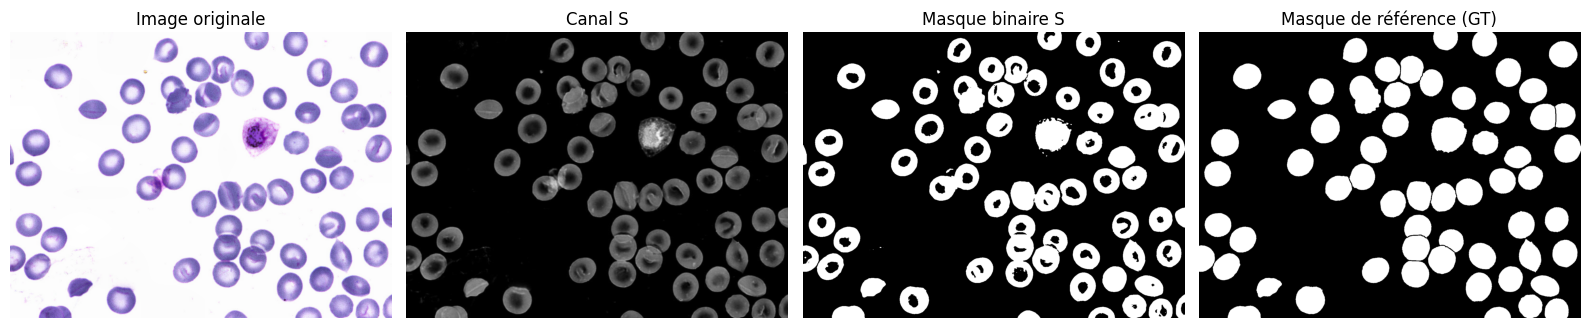

In [ ]:

import matplotlib.pyplot as plt
import cv2

# Prendre une image du train
sample = s_masks_df[s_masks_df['split'] == 'train'].iloc[0]

img_bgr = cv2.imread(sample['image'])
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

img_hsv = cv2.imread(sample['hsv_image'])
S = cv2.split(img_hsv)[1]

pred = cv2.imread(sample['s_mask'], cv2.IMREAD_GRAYSCALE)
gt = cv2.imread(sample['mask'], cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(img_rgb)
plt.title("Image originale")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(S, cmap="gray")
plt.title("Canal S")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(pred, cmap="gray")
plt.title("Masque binaire S")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(gt, cmap="gray")
plt.title("Masque de référence (GT)")
plt.axis("off")

plt.tight_layout()
plt.show()


Résultats existants chargés : aucun recalcul nécessaire.


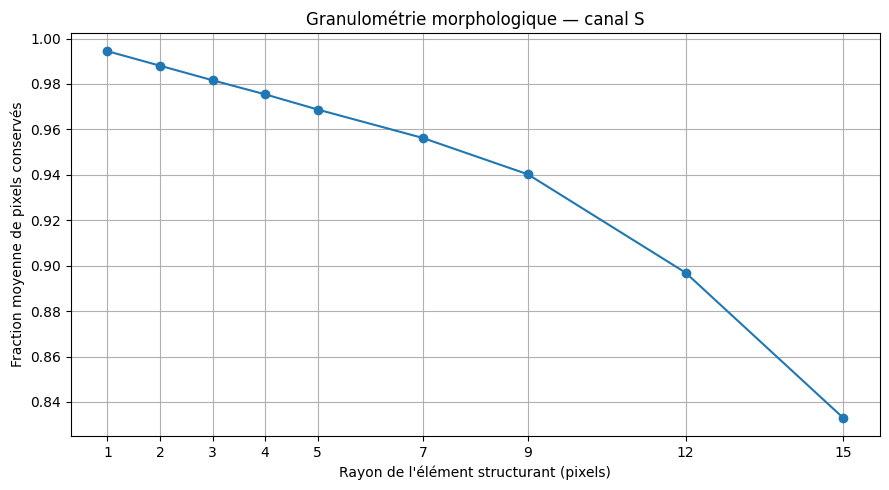

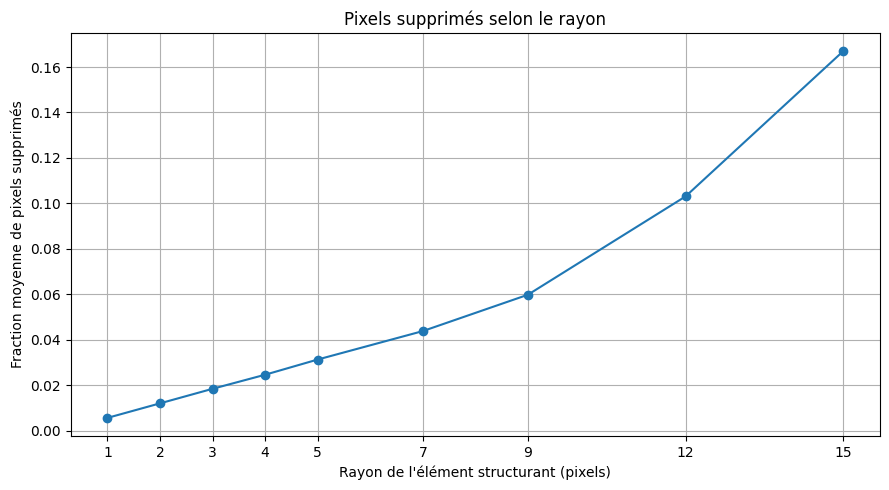


Nombre d'images dans l'analyse : 1063
Détails : /content/drive/MyDrive/projet_morpho/data/granulometry/granulometry_train_detail.csv
Résumé : /content/drive/MyDrive/projet_morpho/data/granulometry/granulometry_train_summary.csv
Configuration : /content/drive/MyDrive/projet_morpho/data/granulometry/granulometry_config.json
Courbes : /content/drive/MyDrive/projet_morpho/data/granulometry


,radius,nombre_images,fraction_conservee_moyenne,fraction_supprimee_moyenne,ecart_type
0,1,1063,0.9944,0.0056,0.0170
1,2,1063,0.9880,0.0120,0.0360
2,3,1063,0.9816,0.0184,0.0510
3,4,1063,0.9754,0.0246,0.0646
4,5,1063,0.9688,0.0312,0.0771
5,7,1063,0.9562,0.0438,0.0956
6,9,1063,0.9402,0.0598,0.1107
7,12,1063,0.8969,0.1031,0.1365
8,15,1063,0.8330,0.1670,0.1659


In [ ]:

# ============================================================
# ÉTAPE 5 — GRANULOMÉTRIE MORPHOLOGIQUE AVEC SAUVEGARDE
# FORCE_REDO = False : charger les résultats ou reprendre
# FORCE_REDO = True  : refaire toute l'analyse
# ============================================================

import os
import json
import hashlib
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

FORCE_REDO = False

CSV_S_MASKS = f'{DATA}/bccd_s_binary_pairs.csv'
GRAN_DIR = f'{DATA}/granulometry'

os.makedirs(GRAN_DIR, exist_ok=True)

DETAIL_CSV = f'{GRAN_DIR}/granulometry_train_detail.csv'
SUMMARY_CSV = f'{GRAN_DIR}/granulometry_train_summary.csv'
CONFIG_JSON = f'{GRAN_DIR}/granulometry_config.json'

# Rayons testés en pixels
RADII = [1, 2, 3, 4, 5, 7, 9, 12, 15]

# None = tout le train
SAMPLE_SIZE = None
RANDOM_STATE = 42

# ============================================================
# 2. CHARGEMENT DES MASQUES S
# ============================================================

if not os.path.exists(CSV_S_MASKS):
    raise FileNotFoundError(
        f"CSV introuvable : {CSV_S_MASKS}\n"
        "Exécute d'abord l'étape 4."
    )

s_masks_df = pd.read_csv(CSV_S_MASKS)

required_columns = {'split', 'image', 's_mask'}
if not required_columns.issubset(s_masks_df.columns):
    raise ValueError(
        f"Colonnes nécessaires absentes : {required_columns}"
    )

train_df = s_masks_df[s_masks_df['split'] == 'train'].copy()

if train_df.empty:
    raise ValueError("Aucune image train dans le CSV.")

if SAMPLE_SIZE is not None and len(train_df) > SAMPLE_SIZE:
    sample_df = train_df.sample(
        n=SAMPLE_SIZE,
        random_state=RANDOM_STATE
    ).copy()
else:
    sample_df = train_df.copy()

sample_df = sample_df.sort_values('image').reset_index(drop=True)

# Vérifier que les fichiers d'entrée existent
missing_masks = [
    path for path in sample_df['s_mask']
    if not os.path.isfile(path)
]

if missing_masks:
    raise FileNotFoundError(
        f"{len(missing_masks)} masques sont absents. "
        f"Exemple : {missing_masks[0]}"
    )

# Empreinte de la liste d'images pour détecter un échantillon différent
sample_signature = hashlib.sha256(
    '\n'.join(sample_df['image'].astype(str)).encode('utf-8')
).hexdigest()

# Paramètres utilisés pour les résultats
config = {
    'method': 'morphological opening',
    'kernel': 'MORPH_ELLIPSE',
    'radii': RADII,
    'sample_size': SAMPLE_SIZE,
    'random_state': RANDOM_STATE,
    'sample_signature': sample_signature,
    'number_of_images': len(sample_df),
    'mask_csv': os.path.abspath(CSV_S_MASKS)
}

# ============================================================
# 3. DÉCIDER : CHARGER, REPRENDRE OU RECOMMENCER
# ============================================================

config_matches = False

if os.path.exists(CONFIG_JSON):
    try:
        with open(CONFIG_JSON, 'r', encoding='utf-8') as f:
            old_config = json.load(f)
        config_matches = (old_config == config)
    except (json.JSONDecodeError, OSError):
        config_matches = False

if FORCE_REDO:
    # Supprimer uniquement les résultats de cette analyse
    for path in [DETAIL_CSV, SUMMARY_CSV]:
        if os.path.exists(path):
            os.remove(path)

    if os.path.exists(CONFIG_JSON):
        os.remove(CONFIG_JSON)

    print("FORCE_REDO=True : nouvelle analyse complète.")

elif not config_matches:
    # Ne pas mélanger des résultats provenant de paramètres différents
    if os.path.exists(DETAIL_CSV):
        backup = f'{DETAIL_CSV}.previous.csv'
        os.replace(DETAIL_CSV, backup)
        print("Ancien détail conservé dans :", backup)

    if os.path.exists(SUMMARY_CSV):
        backup = f'{SUMMARY_CSV}.previous.csv'
        os.replace(SUMMARY_CSV, backup)
        print("Ancien résumé conservé dans :", backup)

    print("Configuration différente : nouveau calcul ou reprise.")

# Sauvegarder la configuration actuelle
with open(CONFIG_JSON, 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

# ============================================================
# 4. CHARGER LES RÉSULTATS OU REPRENDRE LE CALCUL
# ============================================================

# Un résultat est réutilisable uniquement si la configuration
# correspond et si les deux CSV finaux sont disponibles.
if (
    not FORCE_REDO
    and config_matches
    and os.path.isfile(DETAIL_CSV)
    and os.path.isfile(SUMMARY_CSV)
):
    gran_df = pd.read_csv(DETAIL_CSV)
    gran_summary = pd.read_csv(SUMMARY_CSV)

    print("Résultats existants chargés : aucun recalcul nécessaire.")

else:
    # Charger les résultats partiels si la configuration correspond
    if (
        not FORCE_REDO
        and config_matches
        and os.path.isfile(DETAIL_CSV)
    ):
        gran_df = pd.read_csv(DETAIL_CSV)
        print("Reprise à partir des résultats partiels.")
    else:
        gran_df = pd.DataFrame()

    # Vérifier qu'une image n'est considérée terminée que si
    # elle possède tous les rayons attendus.
    completed_images = set()

    if not gran_df.empty and {'image', 'radius'}.issubset(gran_df.columns):
        for image_path, group in gran_df.groupby('image'):
            if set(group['radius'].astype(int)) == set(RADII):
                completed_images.add(image_path)

        # Retirer les lignes incomplètes afin de les recalculer
        gran_df = gran_df[
            gran_df['image'].isin(completed_images)
        ].copy()

    results = gran_df.to_dict('records')

    print(
        f"Images déjà terminées : {len(completed_images)} / "
        f"{len(sample_df)}"
    )

    # ========================================================
    # 5. GRANULOMÉTRIE : OUVERTURES SUCCESSIVES
    # ========================================================

    for _, row in tqdm(
        sample_df.iterrows(),
        total=len(sample_df),
        desc="Granulométrie"
    ):
        image_path = row['image']

        if image_path in completed_images:
            continue

        binary_path = row['s_mask']
        mask = cv2.imread(binary_path, cv2.IMREAD_GRAYSCALE)

        if mask is None:
            print("Masque illisible, image ignorée :", binary_path)
            continue

        binary = np.where(mask > 0, 255, 0).astype(np.uint8)
        initial_area = int(np.count_nonzero(binary))

        # Même si le masque est vide, enregistrer les rayons
        # pour ne pas tenter de le recalculer indéfiniment.
        for radius in RADII:
            if initial_area == 0:
                remaining_area = 0
                retained = np.nan
                removed = np.nan
            else:
                size = 2 * radius + 1

                kernel = cv2.getStructuringElement(
                    cv2.MORPH_ELLIPSE,
                    (size, size)
                )

                opened = cv2.morphologyEx(
                    binary,
                    cv2.MORPH_OPEN,
                    kernel
                )

                remaining_area = int(np.count_nonzero(opened))
                retained = remaining_area / initial_area
                removed = 1 - retained

            results.append({
                'image': image_path,
                's_mask': binary_path,
                'radius': radius,
                'area_initiale': initial_area,
                'area_restante': remaining_area,
                'fraction_conservee': retained,
                'fraction_supprimee': removed
            })

        # Sauvegarder après chaque image terminée.
        # En cas d'interruption, les images précédentes sont conservées.
        gran_df = pd.DataFrame(results)
        gran_df.to_csv(DETAIL_CSV, index=False)

        completed_images.add(image_path)

    # Sauvegarde finale des détails
    gran_df = pd.DataFrame(results)
    gran_df.to_csv(DETAIL_CSV, index=False)

    # ========================================================
    # 6. RÉSUMÉ STATISTIQUE
    # ========================================================

    valid_df = gran_df[
        gran_df['fraction_conservee'].notna()
    ].copy()

    gran_summary = (
        valid_df.groupby('radius')
        .agg(
            nombre_images=('image', 'nunique'),
            fraction_conservee_moyenne=(
                'fraction_conservee', 'mean'
            ),
            fraction_supprimee_moyenne=(
                'fraction_supprimee', 'mean'
            ),
            ecart_type=('fraction_conservee', 'std')
        )
        .reset_index()
    )

    gran_summary.to_csv(SUMMARY_CSV, index=False)

    print("Analyse terminée et résultats sauvegardés.")

# ============================================================
# 7. AFFICHER LES COURBES (À PARTIR DES RÉSULTATS SAUVEGARDÉS)
# ============================================================

gran_summary = gran_summary.sort_values('radius')

plt.figure(figsize=(9, 5))
plt.plot(
    gran_summary['radius'],
    gran_summary['fraction_conservee_moyenne'],
    marker='o'
)
plt.xlabel("Rayon de l'élément structurant (pixels)")
plt.ylabel("Fraction moyenne de pixels conservés")
plt.title("Granulométrie morphologique — canal S")
plt.xticks(RADII)
plt.grid(True)
plt.tight_layout()
plt.savefig(
    f'{GRAN_DIR}/granulometry_retained.png',
    dpi=150
)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(
    gran_summary['radius'],
    gran_summary['fraction_supprimee_moyenne'],
    marker='o'
)
plt.xlabel("Rayon de l'élément structurant (pixels)")
plt.ylabel("Fraction moyenne de pixels supprimés")
plt.title("Pixels supprimés selon le rayon")
plt.xticks(RADII)
plt.grid(True)
plt.tight_layout()
plt.savefig(
    f'{GRAN_DIR}/granulometry_removed.png',
    dpi=150
)
plt.show()

# ============================================================
# 8. RÉSUMÉ FINAL
# ============================================================

print("\nNombre d'images dans l'analyse :", len(sample_df))
print("Détails :", DETAIL_CSV)
print("Résumé :", SUMMARY_CSV)
print("Configuration :", CONFIG_JSON)
print("Courbes :", GRAN_DIR)

display(gran_summary.round(4))


Nombre d'images : 1063


Comparaison Dice:   0%|          | 0/1063 [00:00<?, ?it/s]


===== DICE MOYEN PAR RAYON =====
 radius  nombre_images  dice_moyen  ecart_type  dice_median
      1           1063      0.8975      0.0925       0.9168
      2           1063      0.8954      0.0973       0.9163
      3           1063      0.8932      0.1024       0.9154
      4           1063      0.8910      0.1077       0.9146
      5           1063      0.8883      0.1132       0.9132
      7           1063      0.8831      0.1225       0.9108
      9           1063      0.8756      0.1315       0.9074
     12           1063      0.8537      0.1466       0.8927
     15           1063      0.8174      0.1651       0.8660

===== MEILLEUR RAYON =====
Rayon : 1
Dice moyen : 0.8975


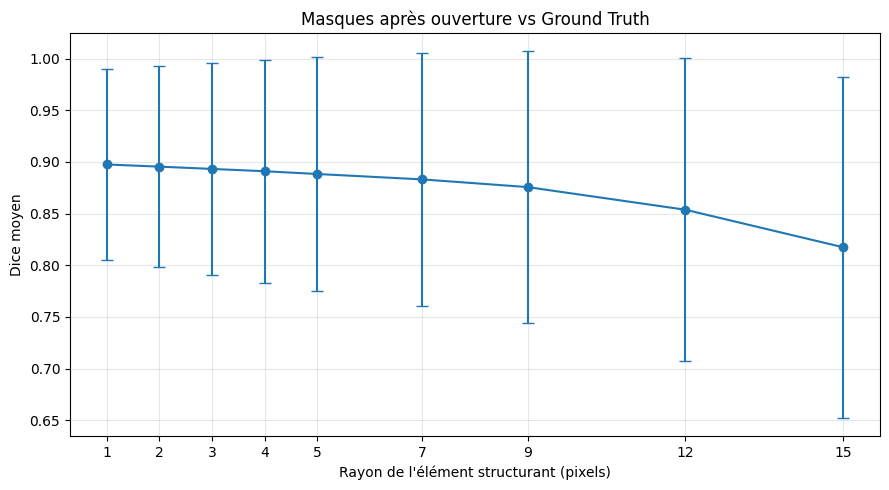


Résultats : /content/drive/MyDrive/projet_morpho/data/granulometry/evaluation


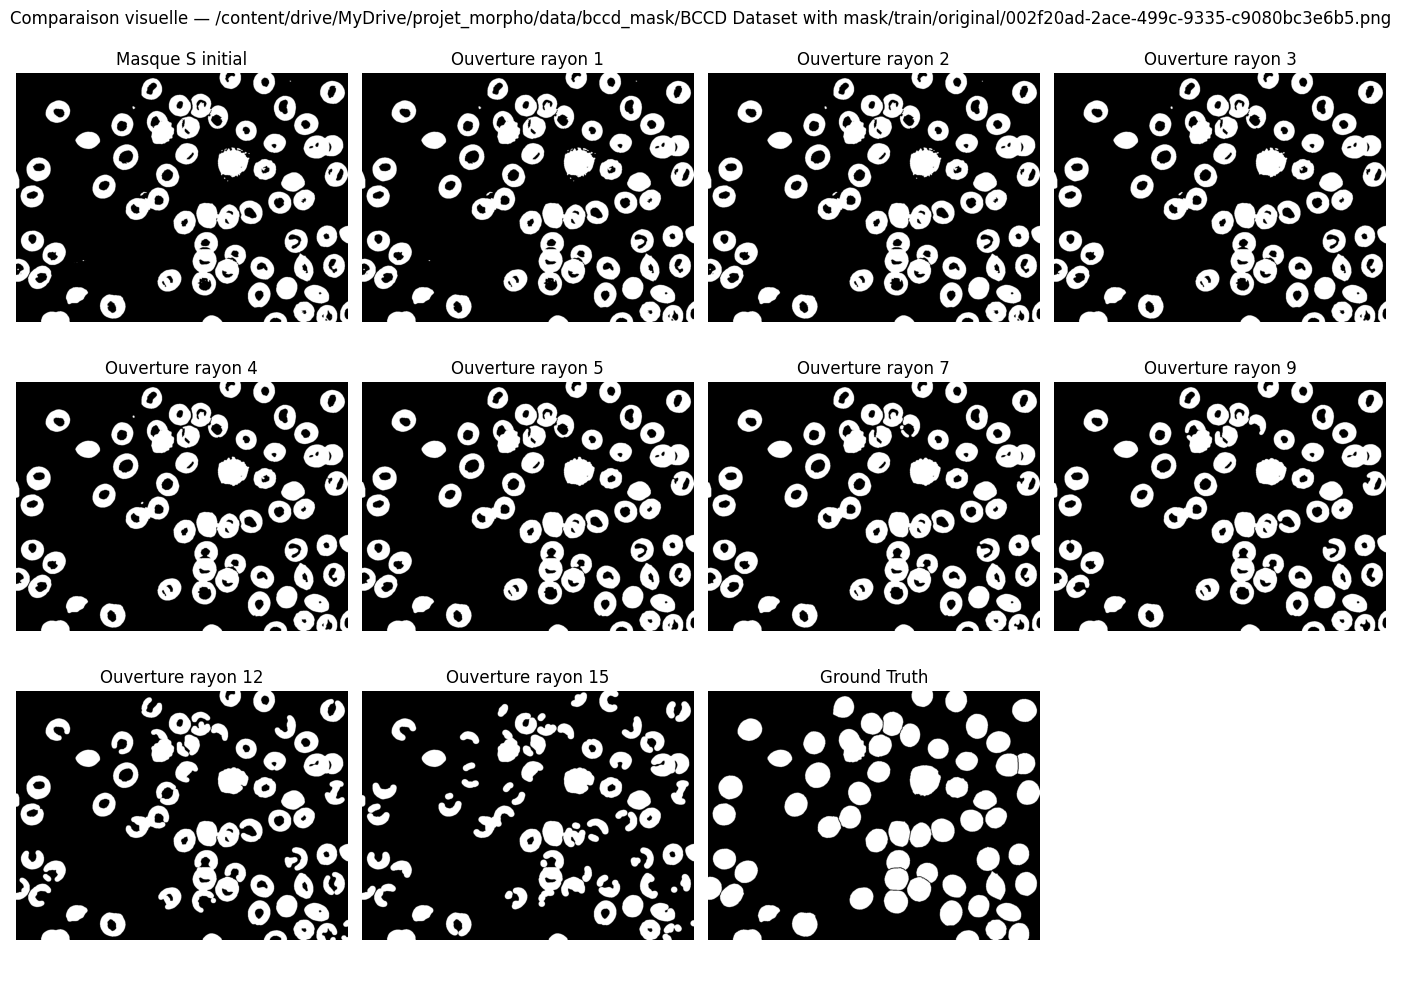

In [ ]:

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# =====================================================
# 1. CHEMINS
# =====================================================

DATA = "/content/drive/MyDrive/projet_morpho/data"

CSV_PATH = os.path.join(DATA, "bccd_s_binary_pairs.csv")
OUT_DIR = os.path.join(DATA, "granulometry", "evaluation")
os.makedirs(OUT_DIR, exist_ok=True)

RADII = [1, 2, 3, 4, 5, 7, 9, 12, 15]

DETAIL_CSV = os.path.join(OUT_DIR, "dice_detail.csv")
SUMMARY_CSV = os.path.join(OUT_DIR, "dice_summary.csv")
PLOT_PATH = os.path.join(OUT_DIR, "dice_comparison.png")

# =====================================================
# 2. CHARGER LES MASQUES EXISTANTS
# =====================================================

df = pd.read_csv(CSV_PATH)
df = df[df["split"].astype(str).str.lower() == "train"].reset_index(drop=True)

print("Nombre d'images :", len(df))

def load_mask(path):
    mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise FileNotFoundError(f"Fichier introuvable : {path}")
    return (mask > 0).astype(np.uint8)

def dice_score(pred, gt):
    pred = pred.astype(bool)
    gt = gt.astype(bool)

    total = pred.sum() + gt.sum()
    if total == 0:
        return 1.0

    intersection = np.logical_and(pred, gt).sum()
    return 2 * intersection / total

def apply_opening(mask, radius):
    # Ouverture temporaire : aucun masque n'est sauvegardé ici
    size = 2 * radius + 1
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (size, size)
    )
    return cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

# =====================================================
# 3. ÉVALUER CHAQUE RAYON CONTRE LE GROUND TRUTH
# =====================================================

records = []

for _, row in tqdm(df.iterrows(), total=len(df), desc="Comparaison Dice"):
    s_mask = load_mask(row["s_mask"])
    gt = load_mask(row["mask"])

    if s_mask.shape != gt.shape:
        raise ValueError(
            f"Dimensions incompatibles pour {row['image']}: "
            f"{s_mask.shape} vs {gt.shape}"
        )

    for radius in RADII:
        opened_mask = apply_opening(s_mask, radius)
        score = dice_score(opened_mask, gt)

        records.append({
            "image": row["image"],
            "radius": radius,
            "dice": score
        })

detail = pd.DataFrame(records)
detail.to_csv(DETAIL_CSV, index=False)

summary = (
    detail.groupby("radius")["dice"]
    .agg(
        nombre_images="count",
        dice_moyen="mean",
        ecart_type="std",
        dice_median="median"
    )
    .reset_index()
)

summary["ecart_type"] = summary["ecart_type"].fillna(0)
summary.to_csv(SUMMARY_CSV, index=False)

print("\n===== DICE MOYEN PAR RAYON =====")
print(summary.round(4).to_string(index=False))

best = summary.loc[summary["dice_moyen"].idxmax()]

print("\n===== MEILLEUR RAYON =====")
print("Rayon :", int(best["radius"]))
print("Dice moyen :", round(best["dice_moyen"], 4))

# =====================================================
# 4. COURBE COMPARATIVE
# =====================================================

plt.figure(figsize=(9, 5))
plt.errorbar(
    summary["radius"],
    summary["dice_moyen"],
    yerr=summary["ecart_type"],
    marker="o",
    capsize=4
)
plt.xlabel("Rayon de l'élément structurant (pixels)")
plt.ylabel("Dice moyen")
plt.title("Masques après ouverture vs Ground Truth")
plt.xticks(RADII)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("\nRésultats :", OUT_DIR)

# =====================================================
# 5. VISUALISER UNE IMAGE AVEC TOUS LES RAYONS
# =====================================================

# Première image disponible : modifier l'index pour en choisir une autre
idx = 0
row = df.iloc[idx]

s_mask = load_mask(row["s_mask"])
gt = load_mask(row["mask"])

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.ravel()

axes[0].imshow(s_mask, cmap="gray")
axes[0].set_title("Masque S initial")

for i, radius in enumerate(RADII, start=1):
    opened = apply_opening(s_mask, radius)
    axes[i].imshow(opened, cmap="gray")
    axes[i].set_title(f"Ouverture rayon {radius}")

axes[10].imshow(gt, cmap="gray")
axes[10].set_title("Ground Truth")

# Le dernier emplacement reste vide
axes[11].axis("off")

for ax in axes:
    ax.axis("off")

plt.suptitle(f"Comparaison visuelle — {row['image']}")
plt.tight_layout()
plt.show()


In [ ]:
import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

DATA = "/content/drive/MyDrive/projet_morpho/data"
df = pd.read_csv(f"{DATA}/bccd_s_binary_pairs.csv")
df = df[df["split"].str.lower() == "train"]

def load_mask(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(path)
    return (img > 0).astype(np.uint8)

def dice_score(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    total = pred.sum() + gt.sum()
    return 1.0 if total == 0 else (
        2 * np.logical_and(pred, gt).sum() / total
    )

scores_initial = []

for _, row in tqdm(df.iterrows(), total=len(df)):
    pred = load_mask(row["s_mask"])
    gt = load_mask(row["mask"])

    if pred.shape != gt.shape:
        raise ValueError(f"Dimensions différentes : {row['image']}")

    scores_initial.append(dice_score(pred, gt))

dice_initial = np.mean(scores_initial)

# Lire le score déjà calculé, sans refaire les ouvertures
summary = pd.read_csv(
    f"{DATA}/granulometry/evaluation/dice_summary.csv"
)
dice_rayon1 = summary.loc[
    summary["radius"] == 1, "dice_moyen"
].iloc[0]

print(f"Dice masque initial (rayon 0) : {dice_initial:.4f}")
print(f"Dice après ouverture (rayon 1) : {dice_rayon1:.4f}")
print(f"Différence : {dice_rayon1 - dice_initial:+.4f}")

  0%|          | 0/1063 [00:00<?, ?it/s]

Dice masque initial (rayon 0) : 0.8991
Dice après ouverture (rayon 1) : 0.8975
Différence : -0.0016


Nombre d'images train : 1063


Évaluation anti-granulométrie:   0%|          | 0/1063 [00:00<?, ?it/s]


===== RÉSULTATS DE LA FERMETURE =====
 radius  nombre_images  dice_moyen  dice_std  dice_median  surface_ajoutee_moyenne  fraction_ajoutee_moyenne
      0           1063      0.8991    0.0895       0.9175                   0.0000                    0.0000
      1           1063      0.9011    0.0868       0.9185                2345.1383                    0.0049
      2           1063      0.9033    0.0836       0.9197                5258.3970                    0.0111
      3           1063      0.9054    0.0808       0.9209                8580.3829                    0.0181
      4           1063      0.9073    0.0785       0.9219               12414.3612                    0.0261
      5           1063      0.9091    0.0764       0.9230               17050.4214                    0.0358
      7           1063      0.9110    0.0738       0.9245               26665.9897                    0.0554
      9           1063      0.9122    0.0724       0.9252               36622.9059       

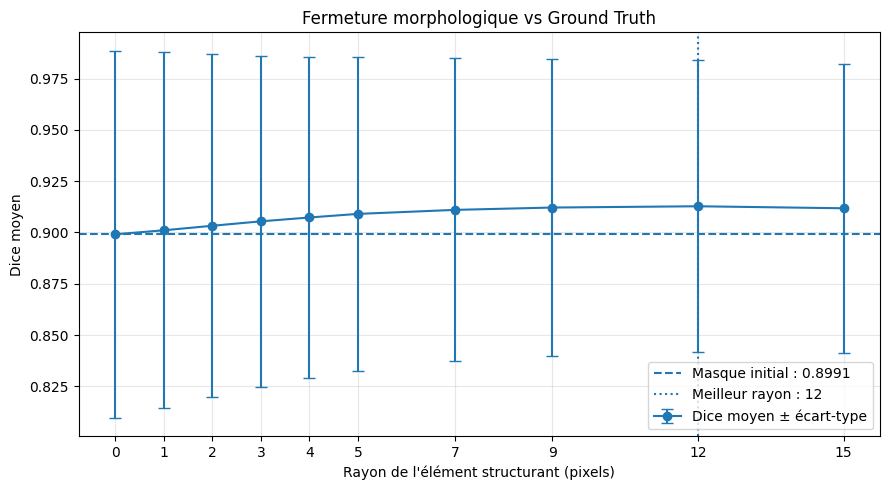

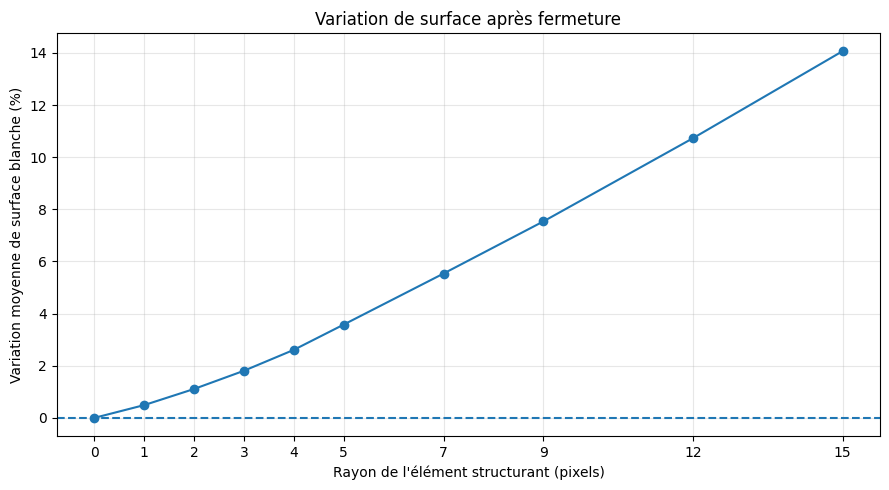

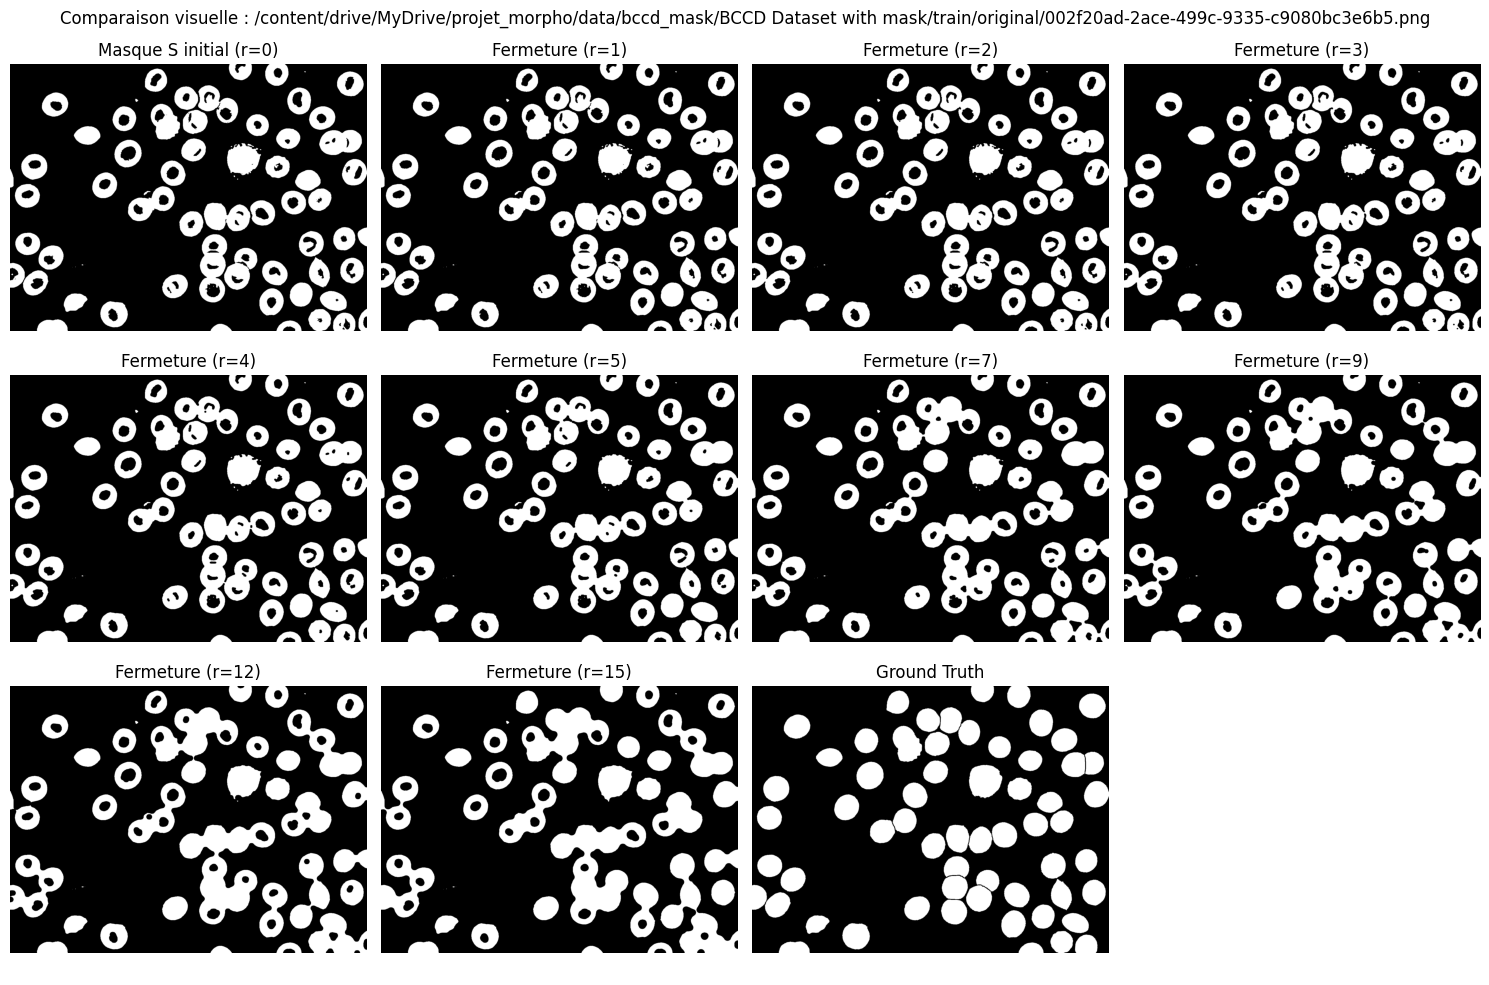


Fichiers sauvegardés dans : /content/drive/MyDrive/projet_morpho/data/anti_granulometry
Détails : /content/drive/MyDrive/projet_morpho/data/anti_granulometry/anti_granulometry_train_detail.csv
Résumé : /content/drive/MyDrive/projet_morpho/data/anti_granulometry/anti_granulometry_train_summary.csv
Courbe Dice : /content/drive/MyDrive/projet_morpho/data/anti_granulometry/dice_comparison.png
Courbe surface : /content/drive/MyDrive/projet_morpho/data/anti_granulometry/area_variation.png
Comparaison visuelle : /content/drive/MyDrive/projet_morpho/data/anti_granulometry/visual_comparison.png


In [ ]:

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

DATA = "/content/drive/MyDrive/projet_morpho/data"

CSV_PATH = os.path.join(DATA, "bccd_s_binary_pairs.csv")

OUT_DIR = os.path.join(DATA, "anti_granulometry")
os.makedirs(OUT_DIR, exist_ok=True)

DETAIL_CSV = os.path.join(OUT_DIR, "anti_granulometry_train_detail.csv")
SUMMARY_CSV = os.path.join(OUT_DIR, "anti_granulometry_train_summary.csv")
DICE_PLOT = os.path.join(OUT_DIR, "dice_comparison.png")
AREA_PLOT = os.path.join(OUT_DIR, "area_variation.png")
VISUAL_PATH = os.path.join(OUT_DIR, "visual_comparison.png")

RADII = [1, 2, 3, 4, 5, 7, 9, 12, 15]
ALL_RADII = [0] + RADII

# ============================================================
# 2. CHARGER LES MASQUES S ET LES MASQUES DE RÉFÉRENCE
# ============================================================

df = pd.read_csv(CSV_PATH)

df_train = df[
    df["split"].astype(str).str.lower() == "train"
].reset_index(drop=True)

if df_train.empty:
    raise ValueError("Aucune image d'entraînement trouvée.")

for col in ["s_mask", "mask"]:
    if col not in df_train.columns:
        raise ValueError(f"Colonne manquante dans le CSV : {col}")

    missing = [
        p for p in df_train[col]
        if not isinstance(p, str) or not os.path.isfile(p)
    ]

    if missing:
        raise FileNotFoundError(
            f"{len(missing)} fichiers manquants dans '{col}'. "
            f"Exemple : {missing[0]}"
        )

print("Nombre d'images train :", len(df_train))

# ============================================================
# 3. FONCTIONS
# ============================================================

def load_mask(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        raise FileNotFoundError(f"Impossible de lire : {path}")

    return (img > 0).astype(np.uint8)


def dice_score(pred, gt):
    pred = pred.astype(bool)
    gt = gt.astype(bool)

    total = pred.sum() + gt.sum()

    if total == 0:
        return 1.0

    intersection = np.logical_and(pred, gt).sum()
    return 2.0 * intersection / total


def apply_closing(mask, radius):
    """
    Fermeture morphologique :
    dilatation puis érosion.
    Le rayon 0 correspond au masque initial.
    """
    if radius == 0:
        return mask.copy()

    size = 2 * radius + 1

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (size, size)
    )

    result = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    return result


# ============================================================
# 4. TESTER LES FERMETURES POUR TOUS LES RAYONS
# ============================================================

records = []

for _, row in tqdm(
    df_train.iterrows(),
    total=len(df_train),
    desc="Évaluation anti-granulométrie"
):
    s_mask = load_mask(row["s_mask"])
    gt = load_mask(row["mask"])

    if s_mask.shape != gt.shape:
        raise ValueError(
            f"Dimensions différentes pour {row['image']} : "
            f"S={s_mask.shape}, GT={gt.shape}"
        )

    initial_area = int(s_mask.sum())

    for radius in ALL_RADII:
        closed_mask = apply_closing(s_mask, radius)

        closed_area = int(closed_mask.sum())

        records.append({
            "image": row["image"],
            "radius": radius,
            "dice": dice_score(closed_mask, gt),
            "surface_initiale": initial_area,
            "surface_apres_fermeture": closed_area,
            "variation_surface": closed_area - initial_area,
            "fraction_surface_ajoutee": (
                (closed_area - initial_area) / initial_area
                if initial_area > 0 else 0.0
            )
        })

detail = pd.DataFrame(records)
detail.to_csv(DETAIL_CSV, index=False)

# ============================================================
# 5. RÉSUMÉ : DICE ET VARIATION DE SURFACE
# ============================================================

summary = (
    detail.groupby("radius")
    .agg(
        nombre_images=("dice", "count"),
        dice_moyen=("dice", "mean"),
        dice_std=("dice", "std"),
        dice_median=("dice", "median"),
        surface_ajoutee_moyenne=("variation_surface", "mean"),
        fraction_ajoutee_moyenne=("fraction_surface_ajoutee", "mean")
    )
    .reset_index()
)

summary["dice_std"] = summary["dice_std"].fillna(0)
summary.to_csv(SUMMARY_CSV, index=False)

print("\n===== RÉSULTATS DE LA FERMETURE =====")
print(summary.round(4).to_string(index=False))

# ============================================================
# 6. CHOISIR LE MEILLEUR RAYON SELON LE DICE
# ============================================================

baseline = summary.loc[
    summary["radius"] == 0, "dice_moyen"
].iloc[0]

closed_results = summary[summary["radius"] > 0]
best = closed_results.loc[
    closed_results["dice_moyen"].idxmax()
]

print("\n===== CONCLUSION =====")
print(f"Dice initial, rayon 0 : {baseline:.4f}")
print(f"Meilleur rayon testé  : {int(best['radius'])}")
print(f"Dice moyen            : {best['dice_moyen']:.4f}")
print(
    f"Différence vs initial : "
    f"{best['dice_moyen'] - baseline:+.4f}"
)

if best["dice_moyen"] > baseline:
    print("La meilleure fermeture améliore le Dice moyen sur le train.")
elif best["dice_moyen"] < baseline:
    print("Aucune fermeture testée ne dépasse le masque initial.")
else:
    print("Meilleur Dice égal à celui du masque initial.")

# ============================================================
# 7. GRAPHIQUE DU DICE
# ============================================================

plt.figure(figsize=(9, 5))

plt.errorbar(
    summary["radius"],
    summary["dice_moyen"],
    yerr=summary["dice_std"],
    marker="o",
    capsize=4,
    label="Dice moyen ± écart-type"
)

plt.axhline(
    baseline,
    linestyle="--",
    label=f"Masque initial : {baseline:.4f}"
)

plt.axvline(
    int(best["radius"]),
    linestyle=":",
    label=f"Meilleur rayon : {int(best['radius'])}"
)

plt.xlabel("Rayon de l'élément structurant (pixels)")
plt.ylabel("Dice moyen")
plt.title("Fermeture morphologique vs Ground Truth")
plt.xticks(ALL_RADII)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(DICE_PLOT, dpi=150, bbox_inches="tight")
plt.show()

# ============================================================
# 8. GRAPHIQUE DE VARIATION DE LA SURFACE BLANCHE
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    summary["radius"],
    summary["fraction_ajoutee_moyenne"] * 100,
    marker="o"
)

plt.axhline(0, linestyle="--")
plt.xlabel("Rayon de l'élément structurant (pixels)")
plt.ylabel("Variation moyenne de surface blanche (%)")
plt.title("Variation de surface après fermeture")
plt.xticks(ALL_RADII)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(AREA_PLOT, dpi=150, bbox_inches="tight")
plt.show()

# ============================================================
# 9. COMPARAISON VISUELLE SUR UNE IMAGE
# ============================================================

idx = 0  # Changer cet index pour visualiser une autre image

row = df_train.iloc[idx]
s_mask = load_mask(row["s_mask"])
gt = load_mask(row["mask"])

fig, axes = plt.subplots(3, 4, figsize=(15, 10))
axes = axes.ravel()

axes[0].imshow(s_mask, cmap="gray")
axes[0].set_title("Masque S initial (r=0)")

for i, radius in enumerate(RADII, start=1):
    closed = apply_closing(s_mask, radius)
    axes[i].imshow(closed, cmap="gray")
    axes[i].set_title(f"Fermeture (r={radius})")

axes[10].imshow(gt, cmap="gray")
axes[10].set_title("Ground Truth")

axes[11].axis("off")

for ax in axes:
    ax.axis("off")

plt.suptitle(f"Comparaison visuelle : {row['image']}")
plt.tight_layout()
plt.savefig(VISUAL_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("\nFichiers sauvegardés dans :", OUT_DIR)
print("Détails :", DETAIL_CSV)
print("Résumé :", SUMMARY_CSV)
print("Courbe Dice :", DICE_PLOT)
print("Courbe surface :", AREA_PLOT)
print("Comparaison visuelle :", VISUAL_PATH)


Nombre d'images train : 1063


  0%|          | 0/1063 [00:00<?, ?it/s]


=== COMPARAISON DES MÉTHODES ===


,methode,dice_moyen,dice_median
0,Masque S initial,0.8991,0.9175
1,Masque S + remplissage des trous,0.9219,0.9432



=== GAIN MOYEN DE DICE ===
0.0227

=== IMAGES AVEC AMÉLIORATION DU DICE ===
1036 / 1063


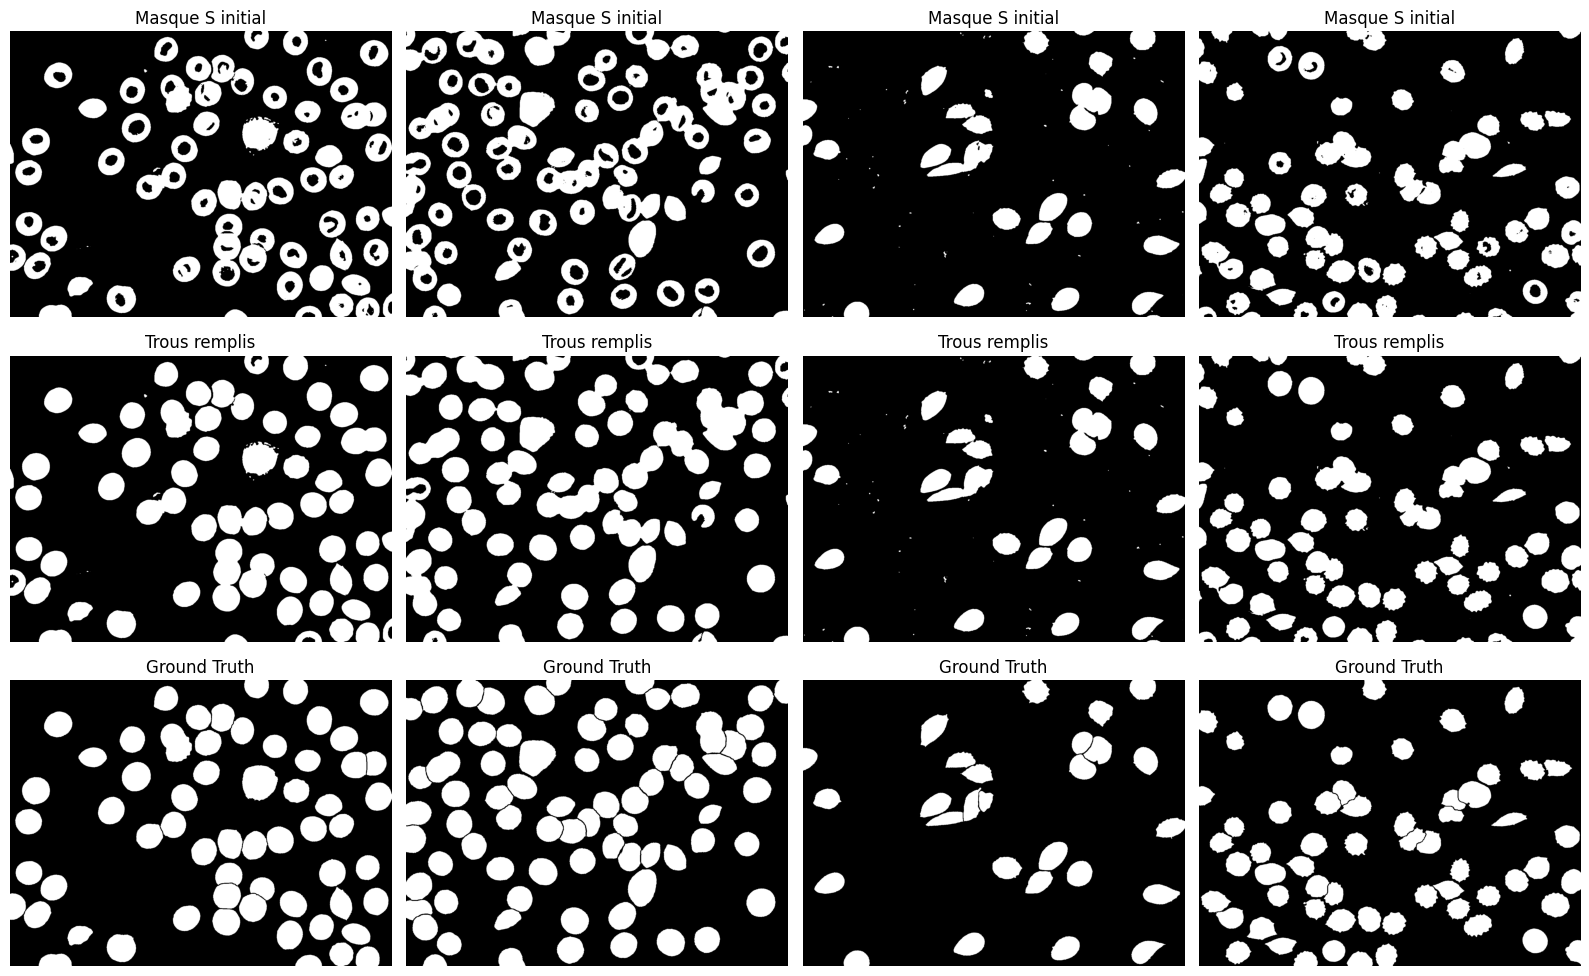


Résultats enregistrés dans : /content/drive/MyDrive/projet_morpho/data/hole_filling


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import ndimage
from tqdm.auto import tqdm

# ============================================================
# 1) CHEMINS
# ============================================================
ROOT = "/content/drive/MyDrive/projet_morpho/data"

CSV_PATH = os.path.join(ROOT, "bccd_s_binary_pairs.csv")

OUT_DIR = os.path.join(ROOT, "hole_filling")
os.makedirs(OUT_DIR, exist_ok=True)

# ============================================================
# 2) CHARGEMENT DES PAIRES EXISTANTES
# ============================================================
df = pd.read_csv(CSV_PATH)

# Évaluation sur TRAIN uniquement
df_train = df[df["split"].str.lower() == "train"].reset_index(drop=True)

print("Nombre d'images train :", len(df_train))

# ============================================================
# 3) FONCTIONS
# ============================================================
def load_binary_mask(path):
    """Charge un masque binaire : blanc = premier plan."""
    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        raise FileNotFoundError(f"Masque introuvable : {path}")

    return (mask > 0).astype(np.uint8)


def dice_score(pred, gt):
    """Calcule le Dice entre deux masques binaires."""
    pred = pred.astype(bool)
    gt = gt.astype(bool)

    denom = pred.sum() + gt.sum()

    if denom == 0:
        return 1.0

    intersection = np.logical_and(pred, gt).sum()
    return 2.0 * intersection / denom


def fill_holes(mask):
    """
    Remplit uniquement les régions noires entièrement
    entourées par les régions blanches.
    """
    filled = ndimage.binary_fill_holes(mask.astype(bool))
    return filled.astype(np.uint8)


# ============================================================
# 4) REMPLISSAGE ET COMPARAISON
# ============================================================
results = []
visual_examples = []

for _, row in tqdm(df_train.iterrows(), total=len(df_train)):

    # Masque S initial et Ground Truth
    mask_s = load_binary_mask(row["s_mask"])
    gt = load_binary_mask(row["mask"])

    # Remplissage des trous
    mask_filled = fill_holes(mask_s)

    # Dice avant et après
    dice_before = dice_score(mask_s, gt)
    dice_after = dice_score(mask_filled, gt)

    # Surface ajoutée
    pixels_added = int(mask_filled.sum() - mask_s.sum())

    results.append({
        "image": row["image"],
        "dice_initial": dice_before,
        "dice_remplissage": dice_after,
        "gain_dice": dice_after - dice_before,
        "pixels_ajoutes": pixels_added
    })

    # Conserver quelques exemples pour l'affichage
    if len(visual_examples) < 6:
        visual_examples.append(
            (row["image"], mask_s.copy(),
             mask_filled.copy(), gt.copy())
        )

# ============================================================
# 5) RÉSULTATS
# ============================================================
results_df = pd.DataFrame(results)

results_df.to_csv(
    os.path.join(OUT_DIR, "hole_filling_train_detail.csv"),
    index=False
)

summary = pd.DataFrame([
    {
        "methode": "Masque S initial",
        "dice_moyen": results_df["dice_initial"].mean(),
        "dice_median": results_df["dice_initial"].median()
    },
    {
        "methode": "Masque S + remplissage des trous",
        "dice_moyen": results_df["dice_remplissage"].mean(),
        "dice_median": results_df["dice_remplissage"].median()
    }
])

summary.to_csv(
    os.path.join(OUT_DIR, "hole_filling_train_summary.csv"),
    index=False
)

print("\n=== COMPARAISON DES MÉTHODES ===")
display(summary.round(4))

print("\n=== GAIN MOYEN DE DICE ===")
print(f"{results_df['gain_dice'].mean():.4f}")

print("\n=== IMAGES AVEC AMÉLIORATION DU DICE ===")
print(
    f"{(results_df['gain_dice'] > 0).sum()} / "
    f"{len(results_df)}"
)

# ============================================================
# 6) VISUALISATION
# ============================================================
fig, axes = plt.subplots(
    3, 4, figsize=(16, 10)
)

for i, (name, original, filled, gt) in enumerate(
    visual_examples[:4]
):
    axes[0, i].imshow(original, cmap="gray")
    axes[0, i].set_title("Masque S initial")

    axes[1, i].imshow(filled, cmap="gray")
    axes[1, i].set_title("Trous remplis")

    axes[2, i].imshow(gt, cmap="gray")
    axes[2, i].set_title("Ground Truth")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()

plot_path = os.path.join(
    OUT_DIR, "hole_filling_visual_comparison.png"
)
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("\nRésultats enregistrés dans :", OUT_DIR)

Nombre d'images Train : 1063
Dossier de sauvegarde : /content/drive/MyDrive/projet_morpho/data/closing12_hole_filling


Évaluation Train:   0%|          | 0/1063 [00:00<?, ?it/s]


=== COMPARAISON DES MÉTHODES ===


,methode,dice_moyen,dice_median,images_ameliorees_vs_initial
0,Masque S initial,0.8991,0.9175,0
1,Remplissage des trous seul,0.9219,0.9432,1036
2,Fermeture r=12 + remplissage,0.9176,0.9333,718



Gain moyen de la combinaison vs remplissage seul : -0.0042


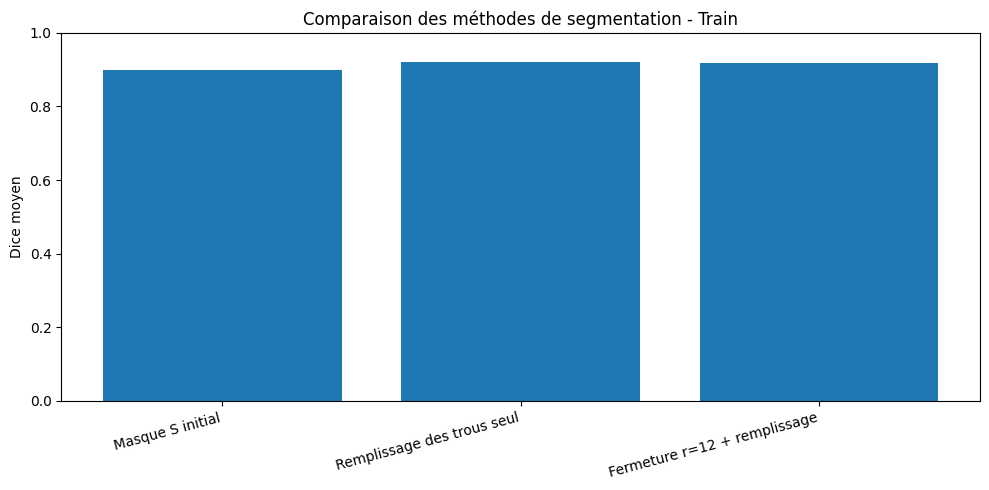

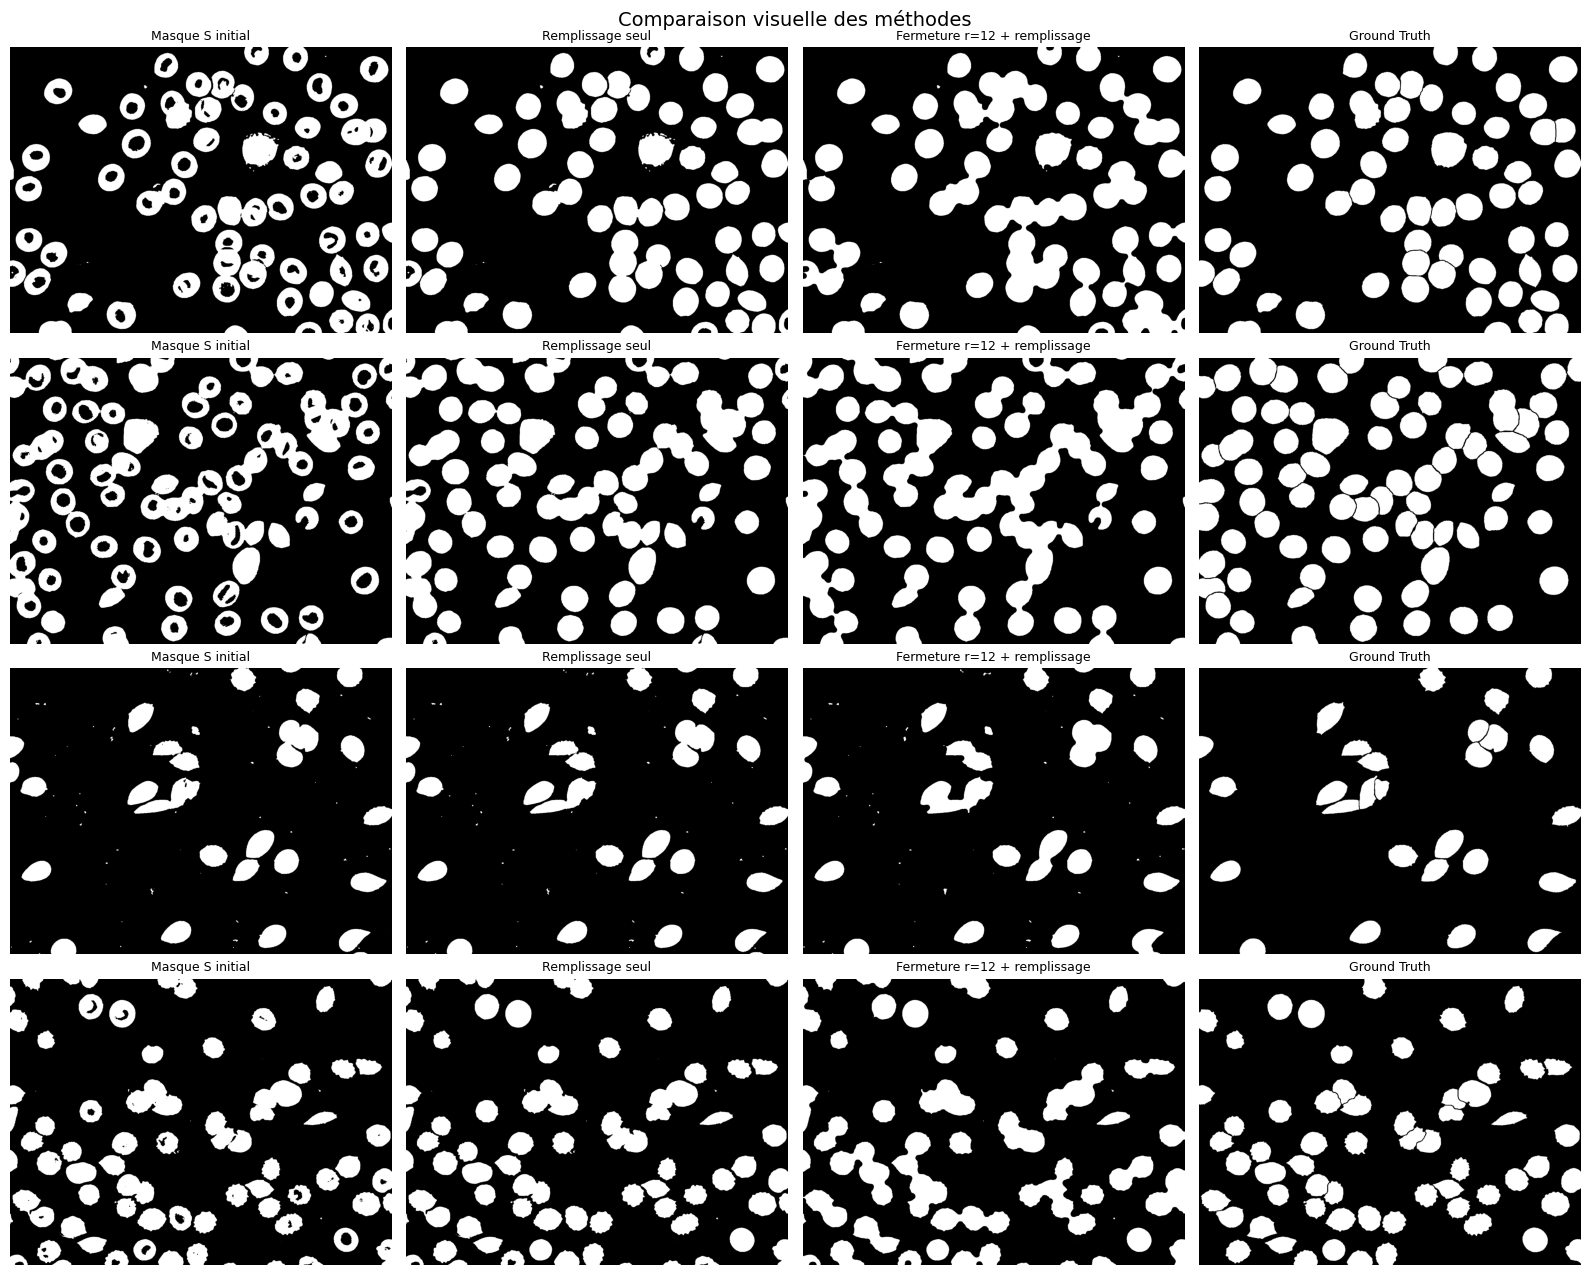

Sauvegarde des masques:   0%|          | 0/1063 [00:00<?, ?it/s]


=== FICHIERS SAUVEGARDÉS ===
Scores détaillés : /content/drive/MyDrive/projet_morpho/data/closing12_hole_filling/closing12_hole_filling_train_detail.csv
Résumé           : /content/drive/MyDrive/projet_morpho/data/closing12_hole_filling/closing12_hole_filling_train_summary.csv
Graphique Dice   : /content/drive/MyDrive/projet_morpho/data/closing12_hole_filling/dice_comparison.png
Comparaison      : /content/drive/MyDrive/projet_morpho/data/closing12_hole_filling/visual_comparison.png
Masques combinés : /content/drive/MyDrive/projet_morpho/data/closing12_hole_filling/train_masks


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import ndimage
from tqdm.auto import tqdm

# ============================================================
# 1. CHEMINS
# ============================================================
ROOT = "/content/drive/MyDrive/projet_morpho/data"

CSV_PATH = os.path.join(ROOT, "bccd_s_binary_pairs.csv")

OUT_DIR = os.path.join(ROOT, "closing12_hole_filling")
os.makedirs(OUT_DIR, exist_ok=True)

RADIUS = 12
KERNEL = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (2 * RADIUS + 1, 2 * RADIUS + 1)
)

# ============================================================
# 2. CHARGEMENT DU DATASET
# ============================================================
df = pd.read_csv(CSV_PATH)

df_train = df[
    df["split"].astype(str).str.lower() == "train"
].reset_index(drop=True)

print("Nombre d'images Train :", len(df_train))
print("Dossier de sauvegarde :", OUT_DIR)

# ============================================================
# 3. FONCTIONS
# ============================================================
def load_binary_mask(path):
    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        raise FileNotFoundError(f"Masque introuvable : {path}")

    return (mask > 0).astype(np.uint8)


def dice_score(pred, gt):
    pred = pred.astype(bool)
    gt = gt.astype(bool)

    denominator = pred.sum() + gt.sum()

    if denominator == 0:
        return 1.0

    intersection = np.logical_and(pred, gt).sum()

    return 2.0 * intersection / denominator


def fill_holes(mask):
    return ndimage.binary_fill_holes(
        mask.astype(bool)
    ).astype(np.uint8)


def apply_closing(mask):
    return cv2.morphologyEx(
        mask.astype(np.uint8),
        cv2.MORPH_CLOSE,
        KERNEL
    )


# ============================================================
# 4. EXPÉRIENCES
# ============================================================
results = []
visual_examples = []

for _, row in tqdm(
    df_train.iterrows(),
    total=len(df_train),
    desc="Évaluation Train"
):
    mask_s = load_binary_mask(row["s_mask"])
    gt = load_binary_mask(row["mask"])

    # Méthode 1 : masque S initial
    initial = mask_s

    # Méthode 2 : remplissage seul
    filled_only = fill_holes(mask_s)

    # Méthode 3 : fermeture r=12 puis remplissage
    closed = apply_closing(mask_s)
    closing_filled = fill_holes(closed)

    # Scores Dice
    dice_initial = dice_score(initial, gt)
    dice_filled = dice_score(filled_only, gt)
    dice_combined = dice_score(closing_filled, gt)

    results.append({
        "image": row["image"],
        "dice_initial": dice_initial,
        "dice_remplissage_seul": dice_filled,
        "dice_fermeture12_remplissage": dice_combined,
        "gain_vs_initial": dice_combined - dice_initial,
        "gain_vs_remplissage_seul": dice_combined - dice_filled,
        "pixels_initial": int(initial.sum()),
        "pixels_remplissage_seul": int(filled_only.sum()),
        "pixels_methode_combinee": int(closing_filled.sum())
    })

    # Garder les quatre premiers exemples pour comparaison visuelle
    if len(visual_examples) < 4:
        visual_examples.append({
            "image": row["image"],
            "initial": initial.copy(),
            "filled": filled_only.copy(),
            "combined": closing_filled.copy(),
            "gt": gt.copy()
        })

# ============================================================
# 5. SAUVEGARDE DES SCORES DÉTAILLÉS
# ============================================================
results_df = pd.DataFrame(results)

detail_path = os.path.join(
    OUT_DIR, "closing12_hole_filling_train_detail.csv"
)

results_df.to_csv(detail_path, index=False)

# ============================================================
# 6. TABLEAU RÉCAPITULATIF
# ============================================================
summary = pd.DataFrame([
    {
        "methode": "Masque S initial",
        "dice_moyen": results_df["dice_initial"].mean(),
        "dice_median": results_df["dice_initial"].median(),
        "images_ameliorees_vs_initial": 0
    },
    {
        "methode": "Remplissage des trous seul",
        "dice_moyen": results_df["dice_remplissage_seul"].mean(),
        "dice_median": results_df["dice_remplissage_seul"].median(),
        "images_ameliorees_vs_initial": int(
            (results_df["dice_remplissage_seul"]
             > results_df["dice_initial"]).sum()
        )
    },
    {
        "methode": "Fermeture r=12 + remplissage",
        "dice_moyen": results_df[
            "dice_fermeture12_remplissage"
        ].mean(),
        "dice_median": results_df[
            "dice_fermeture12_remplissage"
        ].median(),
        "images_ameliorees_vs_initial": int(
            (results_df["dice_fermeture12_remplissage"]
             > results_df["dice_initial"]).sum()
        )
    }
])

summary_path = os.path.join(
    OUT_DIR, "closing12_hole_filling_train_summary.csv"
)

summary.to_csv(summary_path, index=False)

print("\n=== COMPARAISON DES MÉTHODES ===")
display(summary.round(4))

print("\nGain moyen de la combinaison vs remplissage seul :",
      round(
          (
              results_df["dice_fermeture12_remplissage"]
              - results_df["dice_remplissage_seul"]
          ).mean(),
          4
      ))

# ============================================================
# 7. GRAPHIQUE DES DICE MOYENS
# ============================================================
plt.figure(figsize=(10, 5))

plt.bar(
    summary["methode"],
    summary["dice_moyen"]
)

plt.ylabel("Dice moyen")
plt.title("Comparaison des méthodes de segmentation - Train")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()

dice_plot_path = os.path.join(
    OUT_DIR, "dice_comparison.png"
)

plt.savefig(dice_plot_path, dpi=150, bbox_inches="tight")
plt.show()

# ============================================================
# 8. COMPARAISON VISUELLE
# ============================================================
fig, axes = plt.subplots(4, 4, figsize=(16, 13))

for i, example in enumerate(visual_examples):
    images = [
        example["initial"],
        example["filled"],
        example["combined"],
        example["gt"]
    ]

    titles = [
        "Masque S initial",
        "Remplissage seul",
        "Fermeture r=12 + remplissage",
        "Ground Truth"
    ]

    for j, (img, title) in enumerate(zip(images, titles)):
        axes[i, j].imshow(img, cmap="gray", vmin=0, vmax=1)
        axes[i, j].set_title(
            title if i == 0 else title,
            fontsize=9
        )
        axes[i, j].axis("off")

fig.suptitle(
    "Comparaison visuelle des méthodes",
    fontsize=14
)

plt.tight_layout()

visual_path = os.path.join(
    OUT_DIR, "visual_comparison.png"
)

plt.savefig(visual_path, dpi=150, bbox_inches="tight")
plt.show()

# ============================================================
# 9. SAUVEGARDE DES MASQUES COMBINÉS
# ============================================================
# Optionnel : sauvegarder les masques finaux de chaque image Train.
# Les fichiers sont séparés des masques originaux.

SAVE_MASKS = True

if SAVE_MASKS:
    MASKS_DIR = os.path.join(OUT_DIR, "train_masks")
    os.makedirs(MASKS_DIR, exist_ok=True)

    for _, row in tqdm(
        df_train.iterrows(),
        total=len(df_train),
        desc="Sauvegarde des masques"
    ):
        mask_s = load_binary_mask(row["s_mask"])

        combined = fill_holes(apply_closing(mask_s))

        # Nom basé sur le fichier image d'origine
        filename = os.path.splitext(
            os.path.basename(str(row["image"]))
        )[0] + "_closing12_filled.png"

        cv2.imwrite(
            os.path.join(MASKS_DIR, filename),
            combined * 255
        )

# ============================================================
# 10. BILAN
# ============================================================
print("\n=== FICHIERS SAUVEGARDÉS ===")
print("Scores détaillés :", detail_path)
print("Résumé           :", summary_path)
print("Graphique Dice   :", dice_plot_path)
print("Comparaison      :", visual_path)

if SAVE_MASKS:
    print("Masques combinés :", MASKS_DIR)


In [ ]:

import os
import cv2
import numpy as np
import pandas as pd
from scipy.ndimage import binary_fill_holes
from tqdm.auto import tqdm

# ==================================================
# 1. CHEMINS
# ==================================================
ROOT = "/content/drive/MyDrive/projet_morpho/data"
CSV_PATH = os.path.join(ROOT, "bccd_s_binary_pairs.csv")

OUT_DIR = os.path.join(ROOT, "median_filter_train")
os.makedirs(OUT_DIR, exist_ok=True)

# ==================================================
# 2. CHARGEMENT DES PAIRES TRAIN
# ==================================================
df = pd.read_csv(CSV_PATH)
df_train = df[df["split"].str.lower() == "train"].copy()

print("Nombre d'images Train :", len(df_train))

# ==================================================
# 3. CALCUL DU DICE
# ==================================================
def dice_score(pred, gt):
    pred = pred > 0
    gt = gt > 0

    intersection = np.logical_and(pred, gt).sum()
    total = pred.sum() + gt.sum()

    if total == 0:
        return 1.0

    return 2.0 * intersection / total

# ==================================================
# 4. EVALUATION DES TROIS METHODES
# ==================================================
results = []

for _, row in tqdm(df_train.iterrows(), total=len(df_train)):

    # Ground Truth
    gt = cv2.imread(row["mask"], cv2.IMREAD_GRAYSCALE)

    # Masque S initial déjà calculé
    s_mask = cv2.imread(row["s_mask"], cv2.IMREAD_GRAYSCALE)

    if gt is None or s_mask is None:
        print("Image ignorée :", row["image"])
        continue

    # Masques binaires : 0 ou 255
    gt = (gt > 127).astype(np.uint8) * 255
    s_mask = (s_mask > 127).astype(np.uint8) * 255

    # Méthode 1 : masque initial
    initial = s_mask.copy()

    # Méthode 2 : filtre médian 3x3
    median = cv2.medianBlur(s_mask, 3)

    # Méthode 3 : filtre médian + remplissage des trous
    median_binary = median > 0
    median_fill = (
        binary_fill_holes(median_binary).astype(np.uint8) * 255
    )

    # Calcul des Dice
    dice_initial = dice_score(initial, gt)
    dice_median = dice_score(median, gt)
    dice_median_fill = dice_score(median_fill, gt)

    results.append({
        "image": row["image"],
        "dice_initial": dice_initial,
        "dice_median_3x3": dice_median,
        "dice_median_3x3_fill": dice_median_fill
    })

# ==================================================
# 5. MOYENNE DU DICE SUR TRAIN
# ==================================================
detail = pd.DataFrame(results)

summary = pd.DataFrame({
    "Methode": [
        "S initial",
        "S + median 3x3",
        "S + median 3x3 + remplissage des trous"
    ],
    "Dice moyen": [
        detail["dice_initial"].mean(),
        detail["dice_median_3x3"].mean(),
        detail["dice_median_3x3_fill"].mean()
    ]
})

detail.to_csv(
    os.path.join(OUT_DIR, "median_train_detail.csv"),
    index=False
)

summary.to_csv(
    os.path.join(OUT_DIR, "median_train_summary.csv"),
    index=False
)

print("\nRésultats sur TRAIN — Dice uniquement")
print(summary.to_string(index=False))

print("\nNombre d'images évaluées :", len(detail))
print("Résultats sauvegardés dans :", OUT_DIR)


Nombre d'images Train : 1063


  0%|          | 0/1063 [00:00<?, ?it/s]


Résultats sur TRAIN — Dice uniquement
                               Methode  Dice moyen
                             S initial    0.899131
                        S + median 3x3    0.899437
S + median 3x3 + remplissage des trous    0.921487

Nombre d'images évaluées : 1063
Résultats sauvegardés dans : /content/drive/MyDrive/projet_morpho/data/median_filter_train


# PARTIE 3 — Comptage des cellules (dataset « masques », 1209 images)

**Principe**
- **Nombre réel** = nombre de taches blanches du **masque de référence** (les fines lignes noires séparent les cellules collées).
- **Nombre prédit** = nombre de cellules trouvées dans **notre masque** (S → Otsu → remplissage des trous → granulométrie r\* → transformée de distance → watershed).
- **Évaluation** à deux niveaux : (1) total par image : MAE, erreur relative, biais, Pearson ; (2) cellule par cellule : précision, rappel, F1 (IoU > 0,5).

In [ ]:

# ============================================================
# 3.1 FONCTIONS COMMUNES
# À exécuter avant toutes les cellules suivantes
# ============================================================

import warnings
warnings.filterwarnings('ignore')

import os, json, time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import ndimage as ndi
from scipy.stats import pearsonr
from skimage import measure, segmentation, feature, color
from tqdm.auto import tqdm


# ============================================================
# 1. CHARGEMENT DES DONNÉES
# ============================================================

DATA = "/content/drive/MyDrive/projet_morpho/data"
RES_DIR = f"{DATA}/results"

os.makedirs(RES_DIR, exist_ok=True)

df = pd.read_csv(f"{DATA}/bccd_s_binary_pairs.csv")

print(df.split.value_counts())


# ============================================================
# 2. ÉLÉMENT STRUCTURANT
# ============================================================

def disk(r):
    r = max(1, int(round(r)))
    return cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (2 * r + 1, 2 * r + 1)
    )


# ============================================================
# 3. CHARGEMENT DES MASQUES BINAIRES
# ============================================================

def load_bin(path):
    return cv2.imread(
        path,
        cv2.IMREAD_GRAYSCALE
    ) > 127


# ============================================================
# 4. SEGMENTATION
# Canal S -> Otsu déjà calculé -> remplissage des trous
# ============================================================

def segmenter(row):
    return ndi.binary_fill_holes(
        load_bin(row['s_mask'])
    )


# ============================================================
# 5. MÉTRIQUES DE SEGMENTATION
# ============================================================

def dice(a, b):
    s = a.sum() + b.sum()

    return (
        1.0 if s == 0
        else 2 * np.logical_and(a, b).sum() / s
    )


def iou(a, b):
    u = np.logical_or(a, b).sum()

    return (
        1.0 if u == 0
        else np.logical_and(a, b).sum() / u
    )


# ============================================================
# 6. NOMBRE RÉEL : GROUND TRUTH
# 4-CONNEXITÉ
# ============================================================

def compter_gt(gt):

    lab = measure.label(
        gt,
        connectivity=1
    )

    aires = np.bincount(lab.ravel())[1:]

    if len(aires) == 0:
        return 0, lab

    # Élimination des petites régions
    petites = np.where(
        aires < 0.1 * np.median(aires)
    )[0] + 1

    lab[np.isin(lab, petites)] = 0

    # Renumérotation des composantes
    lab, _, _ = segmentation.relabel_sequential(lab)

    return int(lab.max()), lab


# ============================================================
# 7. GRANULOMÉTRIE : SPECTRE GRANULOMÉTRIQUE
# ============================================================

def spectre_granulometrique(mask, facteur=0.25, rmax=100):

    # Réduction de la résolution pour accélérer le calcul
    petit = cv2.resize(
        mask.astype(np.uint8),
        None,
        fx=facteur,
        fy=facteur,
        interpolation=cv2.INTER_NEAREST
    )

    # Rayons des éléments structurants
    rs = np.arange(
        2,
        int(rmax * facteur) + 1
    )

    # Ouvertures morphologiques successives
    G = np.array([
        cv2.morphologyEx(
            petit,
            cv2.MORPH_OPEN,
            disk(r)
        ).sum()
        for r in rs
    ], float)

    # Matière disparue entre deux tailles successives
    PS = -np.diff(np.append(G, 0))[:-1]

    return (
        rs[:-1] / facteur,
        G / max(G[0], 1),
        PS / max(PS.sum(), 1)
    )


# ============================================================
# 8. ESTIMATION DU RAYON TYPIQUE
# ============================================================

def rayon_typique(mask):

    rs, G, PS = spectre_granulometrique(mask)

    if PS.sum() == 0:
        return None

    # Lissage du spectre
    lisse = np.convolve(
        PS,
        [0.25, 0.5, 0.25],
        'same'
    )

    pas = rs[1] - rs[0]

    # Rayon correspondant au maximum du spectre lissé
    return int(
        rs[np.argmax(lisse)] + pas
    )


# ============================================================
# 9. COMPTAGE PRÉDIT : CONNECTED COMPONENTS
# 4-CONNEXITÉ
# ============================================================

def labels_cc(mask):

    lab = measure.label(
        mask,
        connectivity=1
    )

    aires = np.bincount(lab.ravel())[1:]

    if len(aires):

        petites = np.where(
            aires < 0.1 * np.median(aires)
        )[0] + 1

        lab[np.isin(lab, petites)] = 0

    return segmentation.relabel_sequential(lab)[0]


# ============================================================
# 10. COMPTAGE PRÉDIT : WATERSHED
# 4-CONNEXITÉ
# ============================================================

def labels_ws(mask, r, k_dist=0.7, k_haut=0.4, dist=None):

    # Vérification du rayon typique
    if r is None or r <= 0:
        raise ValueError(
            "Le rayon typique doit être positif pour appliquer Watershed."
        )

    # Transformée de distance
    if dist is None:
        dist = ndi.distance_transform_edt(mask)

    # Recherche des maxima locaux
    pics = feature.peak_local_max(
        dist,
        min_distance=max(3, int(k_dist * r)),
        threshold_abs=k_haut * r,
        labels=measure.label(mask, connectivity=1),
        exclude_border=False
    )

    # Création des marqueurs
    marq = np.zeros(mask.shape, np.int32)

    marq[tuple(pics.T)] = np.arange(
        1,
        len(pics) + 1
    )

    # Application de Watershed avec 4-connexité
    lab = segmentation.watershed(
        -dist,
        marq,
        mask=mask,
        connectivity=1
    )

    # Récupération des objets sans sommet
    reste = measure.label(
        mask & (lab == 0),
        connectivity=1
    )

    aires = np.bincount(reste.ravel())[1:]

    # Conservation des régions suffisamment grandes
    garde = np.where(
        aires >= 0.15 * np.pi * r ** 2
    )[0] + 1

    reste[~np.isin(reste, garde)] = 0

    # Renumérotation
    reste = segmentation.relabel_sequential(reste)[0]

    # Attribution de nouveaux labels
    lab[reste > 0] = (
        reste[reste > 0] + lab.max()
    )

    return lab


# ============================================================
# 11. ÉVALUATION CELLULE PAR CELLULE
# ============================================================

def apparier(lab_gt, lab_pred, seuil=0.5):

    # Nombre de cellules réelles et prédites
    n_g = len(np.unique(lab_gt)) - 1
    n_p = len(np.unique(lab_pred)) - 1

    # Pixels appartenant simultanément aux deux masques
    m = (lab_gt > 0) & (lab_pred > 0)

    if m.sum() == 0:
        return 0, n_p, n_g

    # Intersection entre chaque paire de régions
    paires = (
        pd.DataFrame({
            'g': lab_gt[m],
            'p': lab_pred[m]
        })
        .value_counts()
        .reset_index(name='inter')
    )

    # Aires des régions réelles et prédites
    aire_g = np.bincount(lab_gt.ravel())
    aire_p = np.bincount(lab_pred.ravel())

    # Calcul de l'IoU de chaque paire
    paires['iou'] = paires.inter / (
        aire_g[paires.g]
        + aire_p[paires.p]
        - paires.inter
    )

    # Vrais positifs : IoU strictement supérieur au seuil
    vp = int(
        (paires.iou > seuil).sum()
    )

    # Faux positifs et faux négatifs
    fp = n_p - vp
    fn = n_g - vp

    return vp, fp, fn


# ============================================================
# 12. RÉSUMÉ FINAL DES MÉTRIQUES DE COMPTAGE
# ============================================================

def resume_comptage(res, colonnes):

    lignes = []

    for col in colonnes:

        # Erreur entre le comptage prédit et réel
        e = res[col] - res['reel']

        # Somme des VP, FP et FN
        vp = res[f'{col}_VP'].sum()
        fp = res[f'{col}_FP'].sum()
        fn = res[f'{col}_FN'].sum()

        # Précision et rappel
        p = vp / max(vp + fp, 1)
        r_ = vp / max(vp + fn, 1)

        # Corrélation de Pearson
        reel = res['reel'].to_numpy()
        predit = res[col].to_numpy()

        if (
            len(reel) >= 2
            and np.std(reel) > 0
            and np.std(predit) > 0
        ):
            pearson = pearsonr(reel, predit)[0]
        else:
            pearson = np.nan

        # Calcul des métriques
        lignes.append({

            'Méthode': col,

            'MAE': e.abs().mean(),

            'Erreur relative (%)':
                100 * e.abs().sum() / max(res.reel.sum(), 1),

            'Biais': e.mean(),

            'Pearson': pearson,

            'Précision': p,

            'Rappel': r_,

            'F1':
                2 * p * r_ / max(p + r_, 1e-9)
        })

    return (
        pd.DataFrame(lignes)
        .set_index('Méthode')
    )


# ============================================================
# FIN DES FONCTIONS COMMUNES
# ============================================================

print("Fonctions chargées avec succès.")
print("Connexité utilisée : 4-connexité.")


split
train    1063
test      146
Name: count, dtype: int64
Fonctions chargées avec succès.
Connexité utilisée : 4-connexité.


In [ ]:
# ============================================================
# 3.1 bis COPIE LOCALE des masques (évite les blocages de Google Drive)
# À relancer après chaque redémarrage, juste après 3.1 (2-5 min la 1re fois)
# ============================================================
import shutil
LOCAL = "/content/local_data"

def vers_local(p):
    return p.replace(DATA, LOCAL)

for col in ['mask', 's_mask']:
    for p in tqdm(df[col], desc=f"Copie {col}"):
        dst = vers_local(p)
        if not os.path.exists(dst):
            os.makedirs(os.path.dirname(dst), exist_ok=True)
            shutil.copy(p, dst)
    df[col] = df[col].map(vers_local)

print("Copie terminée. Exemple de chemin :", df['mask'][0])


Copie mask:   0%|          | 0/1209 [00:00<?, ?it/s]

Copie s_mask:   0%|          | 0/1209 [00:00<?, ?it/s]

Copie terminée. Exemple de chemin : /content/local_data/bccd_mask/BCCD Dataset with mask/test/mask/e11515b4-9527-4c23-a0ba-43719bacca0d.png


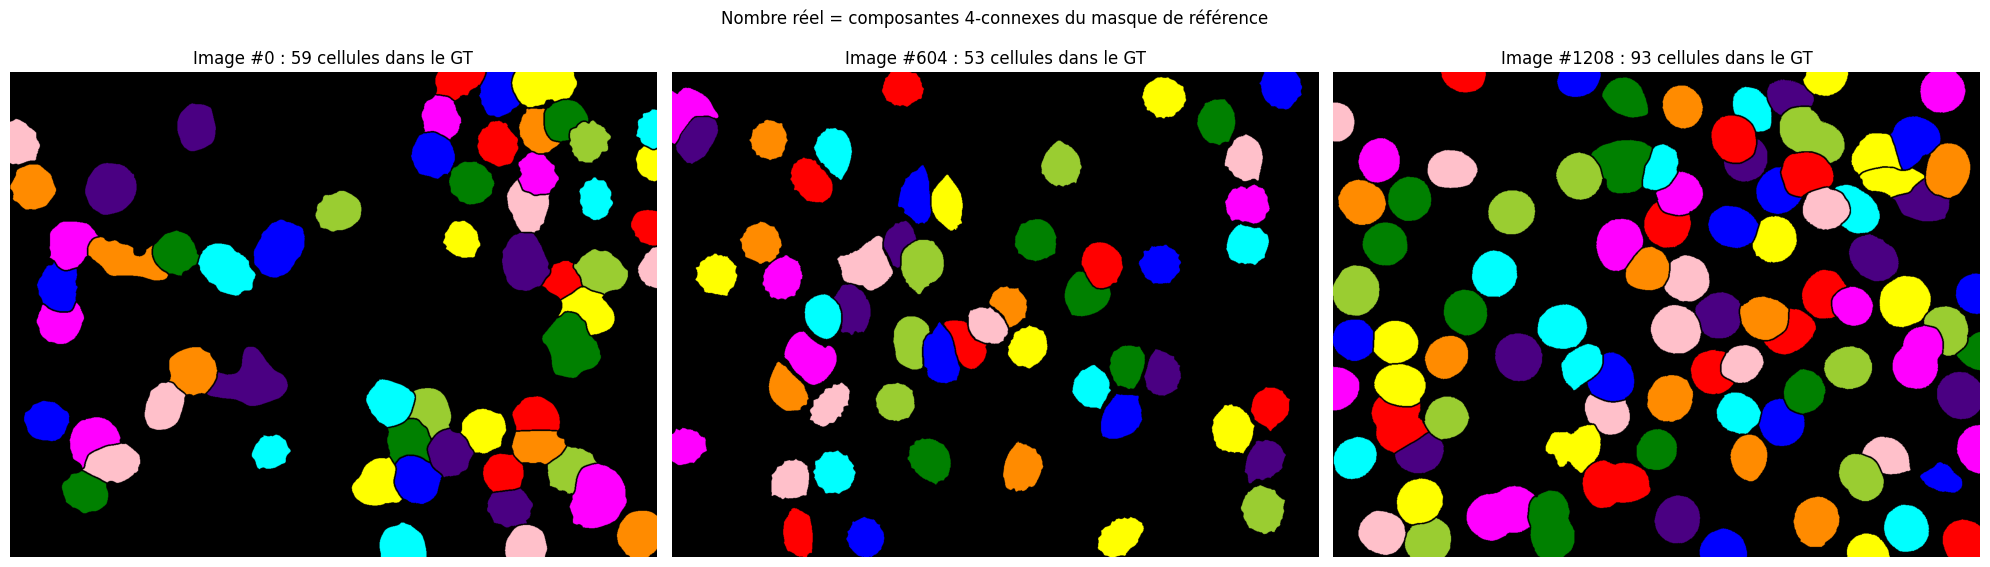

In [ ]:
# ============================================================
# 3.2 VÉRIFICATION : le masque de référence sépare-t-il bien les cellules ?
# Chaque cellule doit avoir SA PROPRE couleur.
# ============================================================
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
for a, i in zip(ax, [0, len(df) // 2, len(df) - 1]):
    n, lab = compter_gt(load_bin(df['mask'][i]))
    a.imshow(color.label2rgb(lab, bg_label=0)); a.set_title(f"Image #{i} : {n} cellules dans le GT"); a.axis('off')
plt.suptitle("Nombre réel = composantes 4-connexes du masque de référence")
plt.tight_layout(); plt.show()


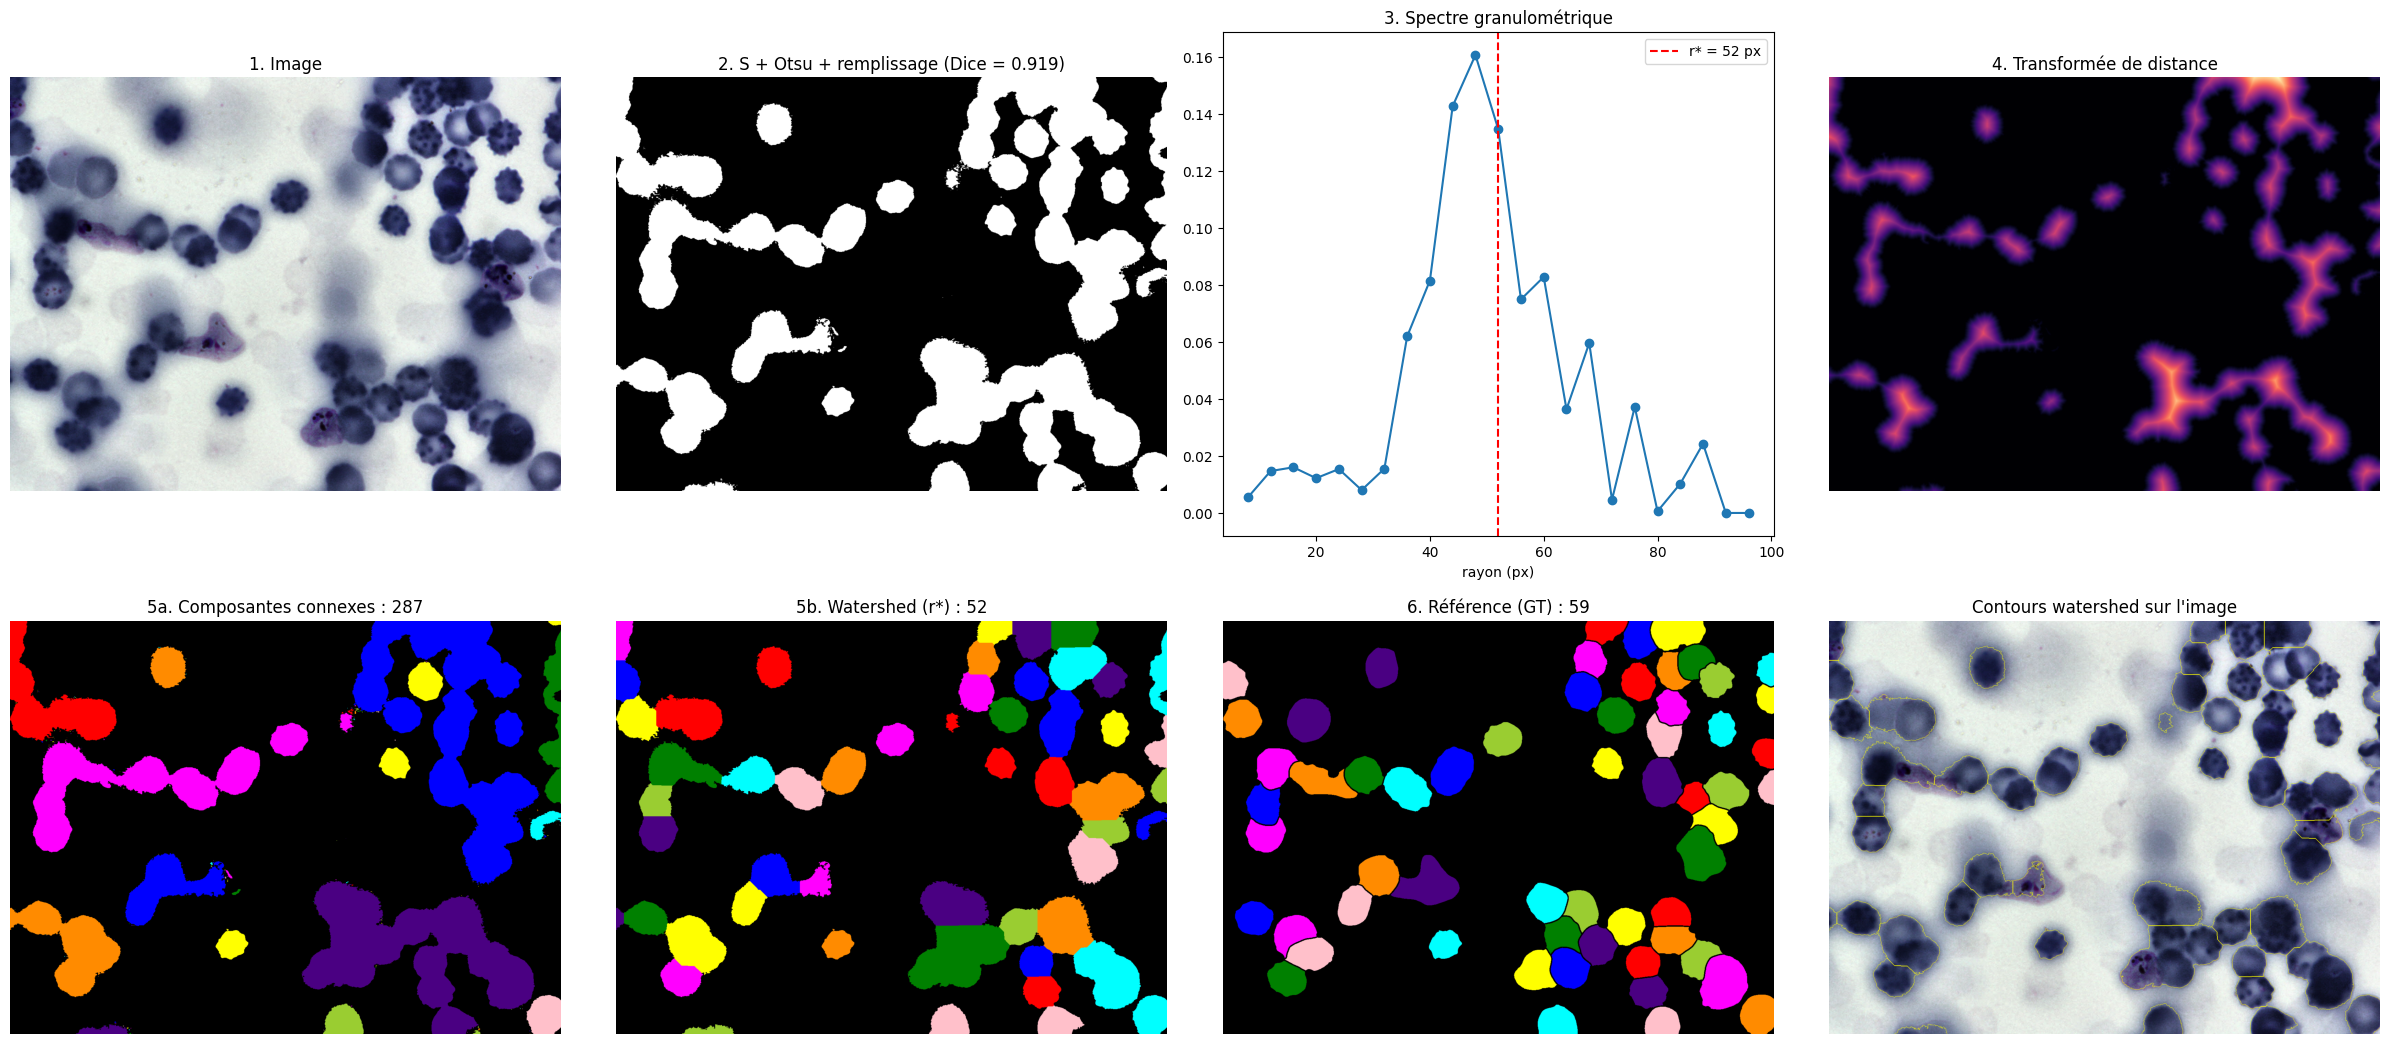

Composantes connexes   prédit = 287 | réel = 59 | VP = 8 FP = 279 FN = 51
Watershed              prédit =  52 | réel = 59 | VP = 38 FP = 14 FN = 21


In [ ]:
# ============================================================
# 3.3 LA CHAÎNE DE COMPTAGE ÉTAPE PAR ÉTAPE (sur une image)
# ============================================================
idx = 0                                     # changer pour voir une autre image
row = df.iloc[idx]
img = cv2.cvtColor(cv2.imread(row['image']), cv2.COLOR_BGR2RGB)
gt = load_bin(row['mask'])
pred = segmenter(row)
r = rayon_typique(pred)
rs, G, PS = spectre_granulometrique(pred)
dist = ndi.distance_transform_edt(pred)
lab_cc, lab_ws = labels_cc(pred), labels_ws(pred, r, dist=dist)
n_gt, lab_gt = compter_gt(gt)

fig, ax = plt.subplots(2, 4, figsize=(24, 11))
ax[0, 0].imshow(img); ax[0, 0].set_title("1. Image")
ax[0, 1].imshow(pred, cmap='gray'); ax[0, 1].set_title(f"2. S + Otsu + remplissage (Dice = {dice(pred, gt):.3f})")
ax[0, 2].plot(rs, PS, 'o-'); ax[0, 2].axvline(r, color='r', ls='--', label=f"r* = {r} px")
ax[0, 2].set(title="3. Spectre granulométrique", xlabel="rayon (px)"); ax[0, 2].legend()
ax[0, 3].imshow(dist, cmap='magma'); ax[0, 3].set_title("4. Transformée de distance")
ax[1, 0].imshow(color.label2rgb(lab_cc, bg_label=0)); ax[1, 0].set_title(f"5a. Composantes connexes : {lab_cc.max()}")
ax[1, 1].imshow(color.label2rgb(lab_ws, bg_label=0)); ax[1, 1].set_title(f"5b. Watershed (r*) : {lab_ws.max()}")
ax[1, 2].imshow(color.label2rgb(lab_gt, bg_label=0)); ax[1, 2].set_title(f"6. Référence (GT) : {n_gt}")
ax[1, 3].imshow(segmentation.mark_boundaries(img, lab_ws, color=(1, 1, 0))); ax[1, 3].set_title("Contours watershed sur l'image")
for a in ax.ravel():
    if a is not ax[0, 2]: a.axis('off')
plt.tight_layout(); plt.show()

for nom, lab in [('Composantes connexes', lab_cc), ('Watershed', lab_ws)]:
    vp, fp, fn = apparier(lab_gt, lab)
    print(f"{nom:<22} prédit = {lab.max():3d} | réel = {n_gt} | VP = {vp} FP = {fp} FN = {fn}")


Déjà calculées : 1063 | à calculer : 0


Comptage train: 0it [00:00, ?it/s]

Temps : 0 s pour 0 images
1063 images | r* médian = 44 px | 82.9 cellules/image en moyenne



,MAE,Erreur relative (%),Biais,Pearson,Précision,Rappel,F1
Méthode,,,,,,,
Composantes connexes,247.478,298.389,213.147,0.153,0.133,0.474,0.208
Watershed (r*),18.338,22.110,-7.158,0.580,0.806,0.737,0.770


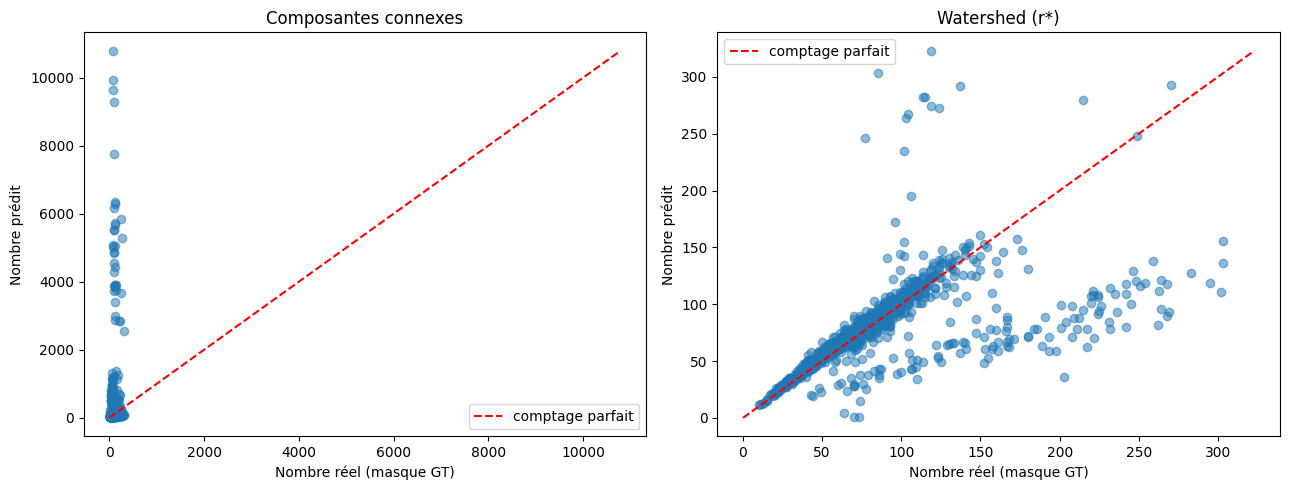

In [ ]:
# ============================================================
# 3.4 ÉVALUATION DU COMPTAGE SUR LE TRAIN (composantes connexes vs watershed)
# Sauvegarde toutes les 20 images + reprise automatique
# ============================================================
N_IMAGES = None              # commencez par 50 (≈ 1 min), puis passez à 300
CSV_OUT = f"{RES_DIR}/comptage_train.csv"

train = df[df.split == 'train'].reset_index(drop=True)
if N_IMAGES:
    train = train.sample(min(N_IMAGES, len(train)), random_state=42).reset_index(drop=True)

# Reprise : on ne recalcule pas les images déjà faites
lignes = pd.read_csv(CSV_OUT).to_dict('records') if os.path.exists(CSV_OUT) else []
deja = {l['image'] for l in lignes}
a_faire = train[~train.image.isin(deja)]
print(f"Déjà calculées : {len(deja)} | à calculer : {len(a_faire)}")

t0 = time.time()
for k, (_, row) in enumerate(tqdm(a_faire.iterrows(), total=len(a_faire), desc="Comptage train")):
    pred = segmenter(row)
    r = rayon_typique(pred)
    if r is None:
        continue
    n_gt, lab_gt = compter_gt(load_bin(row['mask']))
    ligne = {'image': row['image'], 'r_star': r, 'reel': n_gt}
    for nom, lab in [('cc', labels_cc(pred)), ('ws', labels_ws(pred, r))]:
        vp, fp, fn = apparier(lab_gt, lab)
        ligne.update({nom: int(lab.max()), f'{nom}_VP': vp, f'{nom}_FP': fp, f'{nom}_FN': fn})
    lignes.append(ligne)
    if (k + 1) % 20 == 0:                                   # sauvegarde régulière
        pd.DataFrame(lignes).to_csv(CSV_OUT, index=False)

res_train = pd.DataFrame(lignes)
pd.DataFrame(lignes).to_csv(CSV_OUT, index=False)
res_train = res_train[res_train.image.isin(train.image)].reset_index(drop=True)   # uniquement l'échantillon demandé
print(f"Temps : {time.time() - t0:.0f} s pour {len(a_faire)} images")

print(f"{len(res_train)} images | r* médian = {res_train.r_star.median():.0f} px | {res_train.reel.mean():.1f} cellules/image en moyenne\n")
display(resume_comptage(res_train, ['cc', 'ws']).rename(index={'cc': 'Composantes connexes', 'ws': 'Watershed (r*)'}).round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, col, nom in zip(ax, ['cc', 'ws'], ['Composantes connexes', 'Watershed (r*)']):
    a.scatter(res_train.reel, res_train[col], alpha=0.5)
    m = res_train[['reel', col]].values.max()
    a.plot([0, m], [0, m], 'r--', label='comptage parfait'); a.legend()
    a.set(title=nom, xlabel="Nombre réel (masque GT)", ylabel="Nombre prédit")
plt.tight_layout(); plt.show()


# PARTIE 4 — Réglage des paramètres du watershed (train uniquement)

On teste plusieurs valeurs de `k_dist` (distance minimale entre graines) et `k_haut` (hauteur minimale d'un sommet), **exprimées en fraction de r\***.
Critère de choix : le **F1** (cellule par cellule). Le test n'est **jamais** utilisé ici.

In [ ]:

# ============================================================
# 4.1 RECHERCHE DES MEILLEURS PARAMÈTRES SUR LE TRAIN
# ============================================================
# ============================================================
N_REGLAGE = 100                     # images du train utilisées pour le réglage
K_DIST = [0.5, 0.6, 0.7, 0.8, 0.9]
K_HAUT = [0.3, 0.4, 0.5]

reglage = df[df.split == 'train'].sample(N_REGLAGE, random_state=0).reset_index(drop=True)

grille = []

# Tester chaque combinaison
for kd in K_DIST:
    for kh in K_HAUT:

        vp = fp = fn = 0
        erreurs = []

        # Parcourir les images une par une
        for _, row in tqdm(reglage.iterrows(),
                           total=len(reglage),
                           desc=f"kd={kd}, kh={kh}"):

            pred = segmenter(row)
            r = rayon_typique(pred)

            if r is None or r <= 0:
                continue

            n_gt, lab_gt = compter_gt(load_bin(row['mask']))
            dist = ndi.distance_transform_edt(pred)

            lab = labels_ws(pred, r, kd, kh, dist=dist)

            a, b, c = apparier(lab_gt, lab)

            vp += a
            fp += b
            fn += c

            erreurs.append(abs(int(lab.max()) - n_gt))

            del pred, dist, lab, lab_gt

        p = vp / max(vp + fp, 1)
        rc = vp / max(vp + fn, 1)
        f1 = 2 * p * rc / max(p + rc, 1e-9)

        grille.append({
            'k_dist': kd,
            'k_haut': kh,
            'MAE': np.mean(erreurs),
            'Précision': p,
            'Rappel': rc,
            'F1': f1
        })

# Sélectionner la meilleure combinaison
grille = pd.DataFrame(grille).sort_values(
    'F1', ascending=False
).reset_index(drop=True)

best = grille.iloc[0]

PARAMS = {
    'k_dist': float(best.k_dist),
    'k_haut': float(best.k_haut)
}

# Sauvegarder uniquement les meilleurs paramètres
with open(f"{RES_DIR}/parametres_retenus.json", 'w') as f:
    json.dump(PARAMS, f)

print("Meilleurs paramètres :", PARAMS)
print("Résultats de la meilleure combinaison :")
print(best)


kd=0.5, kh=0.3:   0%|          | 0/100 [00:00<?, ?it/s]

kd=0.5, kh=0.4:   0%|          | 0/100 [00:00<?, ?it/s]

kd=0.5, kh=0.5:   0%|          | 0/100 [00:00<?, ?it/s]

kd=0.6, kh=0.3:   0%|          | 0/100 [00:00<?, ?it/s]

kd=0.6, kh=0.4:   0%|          | 0/100 [00:00<?, ?it/s]

kd=0.6, kh=0.5:   0%|          | 0/100 [00:00<?, ?it/s]

... (6 outputs left out)

kd=0.9, kh=0.3:   0%|          | 0/100 [00:00<?, ?it/s]

kd=0.9, kh=0.4:   0%|          | 0/100 [00:00<?, ?it/s]

kd=0.9, kh=0.5:   0%|          | 0/100 [00:00<?, ?it/s]

Meilleurs paramètres : {'k_dist': 0.8, 'k_haut': 0.5}
Résultats de la meilleure combinaison :
k_dist        0.800000
k_haut        0.500000
MAE          15.760000
Précision     0.790630
Rappel        0.729009
F1            0.758570
Name: 0, dtype: float64


# PARTIE 5 — Évaluation finale sur le TEST (à lancer une seule fois)

Toute la chaîne est maintenant figée (choisie sur le train). On mesure sur les **146 images de test** :
- **Segmentation** : Dice et IoU (H1 : IoU > 0,75) ;
- **Comptage** : MAE, erreur relative, biais, Pearson, précision, rappel, F1 ;
- **Temps de calcul** par image (pour H3).

In [13]:

# ============================================================
# 5.1 ÉVALUATION FINALE SUR LE TEST
# ============================================================

PARAMS = json.load(open(f"{RES_DIR}/parametres_retenus.json"))
test = df[df.split == 'test'].reset_index(drop=True)

lignes = []

for _, row in tqdm(test.iterrows(), total=len(test), desc="Test final"):

    gt = load_bin(row['mask'])

    t0 = time.time()

    s_otsu = load_bin(row['s_mask'])
    pred = ndi.binary_fill_holes(s_otsu)

    r = rayon_typique(pred)

    lab_ws = labels_ws(pred, r, **PARAMS) if r else np.zeros(gt.shape, np.int32)

    t_tot = time.time() - t0

    n_gt, lab_gt = compter_gt(gt)
    lab_cc = labels_cc(pred)

    ligne = {
        'image': row['image'],
        'r_star': r,
        'reel': n_gt,
        'dice_otsu': dice(s_otsu, gt),
        'iou_otsu': iou(s_otsu, gt),
        'dice_final': dice(pred, gt),
        'iou_final': iou(pred, gt),
        'temps_ms': 1000 * t_tot
    }

    for nom, lab in [('cc', lab_cc), ('ws', lab_ws)]:

        vp, fp, fn = apparier(lab_gt, lab)

        ligne.update({
            nom: int(lab.max()),
            f'{nom}_VP': vp,
            f'{nom}_FP': fp,
            f'{nom}_FN': fn
        })

    lignes.append(ligne)

    del gt, s_otsu, pred, lab_ws, lab_cc, lab_gt

# Rassembler les résultats en mémoire
res_test = pd.DataFrame(lignes)

# ============================================================
# AFFICHAGE DES RÉSULTATS DE SEGMENTATION
# ============================================================

print(f"=== SEGMENTATION ({len(res_test)} images de test) ===")

seg = pd.DataFrame({
    'Dice moyen': [
        res_test.dice_otsu.mean(),
        res_test.dice_final.mean()
    ],
    'IoU moyen': [
        res_test.iou_otsu.mean(),
        res_test.iou_final.mean()
    ],
    'IoU écart-type': [
        res_test.iou_otsu.std(),
        res_test.iou_final.std()
    ],
}, index=[
    'S + Otsu (baseline)',
    'S + Otsu + remplissage des trous'
])

display(seg.round(4))

print(
    f"H1 (IoU > 0,75) : "
    f"{'VALIDÉE' if res_test.iou_final.mean() > 0.75 else 'NON validée'} "
    f"— {(res_test.iou_final > 0.75).mean():.0%} des images dépassent 0,75"
)

# ============================================================
# AFFICHAGE DES RÉSULTATS DE COMPTAGE
# ============================================================

print(f"\n=== COMPTAGE (paramètres : {PARAMS}) ===")

display(
    resume_comptage(res_test, ['cc', 'ws'])
    .rename(index={
        'cc': 'Composantes connexes',
        'ws': 'Watershed (r*)'
    })
    .round(3)
)

print(
    f"\nTemps moyen (segmentation + granulométrie + watershed) : "
    f"{res_test.temps_ms.mean():.0f} ms / image (CPU)"
)


Test final:   0%|          | 0/146 [00:00<?, ?it/s]

=== SEGMENTATION (146 images de test) ===


,Dice moyen,IoU moyen,IoU écart-type
S + Otsu (baseline),0.8894,0.8171,0.1408
S + Otsu + remplissage des trous,0.9121,0.8552,0.1413


H1 (IoU > 0,75) : VALIDÉE — 92% des images dépassent 0,75

=== COMPTAGE (paramètres : {'k_dist': 0.8, 'k_haut': 0.5}) ===


,MAE,Erreur relative (%),Biais,Pearson,Précision,Rappel,F1
Méthode,,,,,,,
Composantes connexes,251.589,303.269,222.233,0.023,0.127,0.466,0.199
Watershed (r*),26.623,32.092,0.281,0.010,0.744,0.746,0.745



Temps moyen (segmentation + granulométrie + watershed) : 828 ms / image (CPU)
